# Tensorial t-ESSTV Figure 5 + Dynamic-λ Ablation

This notebook preserves the uploaded `tensorial_esstv_figure5.py`
implementation and adds a self-contained extension at the end.

The only notebook-specific change to the original source is that the
terminal command-line call `main()` is disabled. All published Donor 5
parameters and tensorial model equations are unchanged.

**APR18 workbook configured below**

`E:\pt\dataset\APR18 SS SAOS STEPS LAOS UDLAOS.xlsx`

Run the notebook from top to bottom. The extension compares:

1. instantaneous equilibrium structure, `λ(t) = λ_ss(γdot(t))`;
2. dynamic structure driven by measured total shear rate;
3. the uploaded dynamic structure driven by plastic shear rate.

The first comparison (1 vs 2) isolates the value of structural memory.
No parameter is refitted in this first ablation.


In [1]:
#!/usr/bin/env python3
"""Reproduce the tensorial ESSTV curves in Armstrong et al. (2022).

Model source
------------
Armstrong et al., Frontiers in Physics 10, 889065 (2022), Tables 1-3.
The default parameter set is the published Donor 5 tensorial best fit.

Expected public workbook
------------------------
APR18 SS SAOS STEPS LAOS UDLAOS.xlsx
DOI: https://doi.org/10.17632/6jjryg2f8v.1

The script searches the workbook for:
  * one steady-state sheet;
  * one step-up/step-down sheet arranged in five-column experiment blocks;
  * 0.1 -> 1, 2.5, 5 1/s step-ups;
  * the measured step protocols, independently of potentially incorrect titles.

Install
-------
python -m pip install numpy pandas scipy matplotlib openpyxl

Run
---
python tensorial_esstv_figure5_v3.py \
    --data "APR18 SS SAOS STEPS LAOS UDLAOS.xlsx"

Numerical self-test (does not need the workbook)
-------------------------------------------------
python tensorial_esstv_figure5_v3.py --synthetic

Outputs
-------
tensorial_esstv_figure5_output/
  figure5_workbook_baseline.png/pdf
  figure5_paper_reproduction.png/pdf
  lambda_evolution.png/pdf
  protocol_audit.csv
  lambda_summary.csv
  paper_lambda_comparison.csv
  parameters.csv
  steady_state_model.csv
  steady_state_model_<block>.csv
  steady_state_block_audit.csv
  steady_state_cost_comparison.csv
  step_*.csv
  metrics.csv
  paper_cost_comparison.csv

Important reproducibility note
------------------------------
The paper reports rounded parameters and does not publish its MATLAB source or
all numerical initialisation details. This script implements the printed model
equations directly and obtains every step initial condition by relaxing the
full tensorial model at the nominal pre-shear rate. It is therefore suitable
for scientific/numerical reproduction. Small deviations from the printed curve
can remain because the unrounded parameters used by the authors are unavailable.
The APR18 workbook contains two nearly identical steady-state blocks (the
second is marked ``NEW:``). V3 keeps them separate and never pools them as
independent observations.
"""

from __future__ import annotations

import argparse
import re
from dataclasses import asdict, dataclass
from pathlib import Path
from typing import Callable

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.integrate import solve_ivp


EPS = 1.0e-12
PAPER_FCOST_SS = 0.0043
PAPER_FCOST_TRANS = 0.0232


In [2]:
# ============================================================================
# 1. PUBLISHED DONOR 5 PARAMETERS
# ============================================================================


@dataclass(frozen=True)
class Params:
    """Tensorial ESSTV parameters from the paper's Donor 5 row."""

    # Plasma + individual RBC White-Metzner/Cross branch
    mu0_c: float = 0.0138       # Pa s
    muinf_c: float = 0.0054     # Pa s
    tau_c: float = 0.029        # s

    # Rouleaux structure and steady contribution
    tau_break: float = 1.582    # s
    tau_aggr: float = 0.192     # s
    mu_r: float = 0.099         # Pa s
    sigma_y0: float = 0.0039    # Pa

    # Transient/tensorial contribution
    tau_lambda: float = 1.4582  # s
    G_r: float = 0.2646         # Pa
    G_c: float = 0.5138         # Pa

    # Fixed for blood in the paper
    gamma0_r: float = 1.0
    d: float = 0.5
    m: float = 1.5


PAPER_PARAMS = Params()


@dataclass
class StepTest:
    """One measured shear-rate step experiment."""

    title: str
    # pre_rate and target_rate are the canonical rates inferred from the
    # measured shear-rate channel.  Title rates are retained separately so a
    # bad workbook label can never silently change the experiment identity.
    pre_rate: float
    target_rate: float
    data: pd.DataFrame
    title_pre_rate: float = np.nan
    title_target_rate: float = np.nan
    measured_pre_rate: float = np.nan
    measured_target_rate: float = np.nan
    source_column: int = -1
    protocol_warning: str = ""


# State vector indices. Keeping names here makes the ODE easier to audit.
I_LAM = 0
I_GAMMA_E = 1
I_SC_XY = 2
I_SC_XX = 3
I_SR_XY = 4
I_SR_XX = 5
I_SR_YY = 6
I_SR_ZZ = 7
N_STATE = 8


In [3]:
# ============================================================================
# 2. DATA LOADING
# ============================================================================


def clean_text(value: object) -> str:
    if pd.isna(value):
        return ""
    return str(value).replace("\n", " ").strip()


def parse_rates(title: str) -> tuple[float, float]:
    """Parse titles such as '5-->.1(1/s)' or '0.1 -> 5 s^-1'."""

    text = title.lower().replace("−", "-").replace("→", "->")
    number = r"(?:\d+(?:\.\d*)?|\.\d+)"
    match = re.search(
        rf"(?P<a>{number})\s*(?:--+>|-+>|\bto\b)\s*(?P<b>{number})",
        text,
    )
    if match is None:
        return np.nan, np.nan
    return float(match.group("a")), float(match.group("b"))


def canonical_rate(value: float) -> float:
    """Snap a measured rate to a common experimental setpoint when close."""

    common = (0.0, 0.1, 0.25, 0.5, 1.0, 2.5, 5.0, 10.0, 300.0)
    for expected in common:
        if np.isclose(value, expected, rtol=0.08, atol=0.03):
            return float(expected)
    return float(np.round(value, 6))


def measured_protocol(frame: pd.DataFrame) -> tuple[float, float]:
    """Robust initial/final setpoints from the measured shear-rate channel."""

    shear = frame["shear_rate"].to_numpy(float)
    window = max(3, min(5, len(shear) // 10))
    pre = float(np.median(shear[:window]))
    tail_window = max(5, min(10, len(shear) // 5))
    target = float(np.median(shear[-tail_window:]))
    return pre, target


def find_workbook(explicit: str | None) -> Path:
    if explicit:
        path = Path(explicit).expanduser().resolve()
        if path.exists():
            return path
        raise FileNotFoundError(f"Workbook not found: {path}")

    here = Path(__file__).resolve().parent
    candidates = [
        here / "APR18 SS SAOS STEPS LAOS UDLAOS.xlsx",
        here / "APR18.xlsx",
        here / "JUN18.xlsx",
        here / "JUN18(1).xlsx",
    ]
    for path in candidates:
        if path.exists():
            return path

    raise FileNotFoundError(
        "Could not find the rheology workbook.\n"
        "For paper Figure 5, download:\n"
        "  APR18 SS SAOS STEPS LAOS UDLAOS.xlsx\n"
        "  https://doi.org/10.17632/6jjryg2f8v.1\n"
        "Then place it beside this script or pass --data PATH."
    )


def choose_sheet(sheet_names: list[str], keyword: str, explicit: str | None) -> str:
    if explicit:
        if explicit not in sheet_names:
            raise ValueError(
                f"Sheet {explicit!r} not found. Available sheets: {sheet_names}"
            )
        return explicit

    aliases = {
        "steady": ("steady", "ss"),
        "step": ("step",),
    }.get(keyword, (keyword,))
    matches = []
    for name in sheet_names:
        normalized = name.lower()
        if any(
            alias in normalized
            if len(alias) > 2
            else re.search(rf"\b{re.escape(alias)}\b", normalized) is not None
            for alias in aliases
        ):
            matches.append(name)
    if not matches:
        raise ValueError(
            f"Could not find a sheet containing {keyword!r}. "
            f"Available sheets: {sheet_names}"
        )
    return matches[0]


def parse_col_pair(text: str) -> tuple[int, int]:
    values = [int(x.strip()) for x in text.split(",")]
    if len(values) != 2:
        raise ValueError("--ss-cols must look like 0,1")
    return values[0], values[1]


def read_steady_state_blocks(
    workbook: Path,
    sheet: str | None,
    cols: tuple[int, int],
) -> dict[str, pd.DataFrame]:
    """Read contiguous SS blocks without pooling duplicated shear rates.

    APR18 has one 16-point block followed by a second block introduced by the
    label ``NEW:``. Twelve values are exact copies, so treating all rows as
    independent observations would double-count the same measurements. Each
    contiguous numeric block is therefore retained as an alternative dataset.
    """

    excel = pd.ExcelFile(workbook)
    sheet_name = choose_sheet(excel.sheet_names, "steady", sheet)
    raw = pd.read_excel(workbook, sheet_name=sheet_name, header=None)
    shear_col, stress_col = cols

    if max(shear_col, stress_col) >= raw.shape[1]:
        raise ValueError(
            f"SS columns {cols} exceed the {raw.shape[1]} columns in {sheet_name!r}."
        )

    shear = pd.to_numeric(raw.iloc[:, shear_col], errors="coerce")
    stress = pd.to_numeric(raw.iloc[:, stress_col], errors="coerce")
    valid = (
        np.isfinite(shear)
        & np.isfinite(stress)
        & (shear > 0.0)
        & (stress > 0.0)
    )
    valid_rows = np.flatnonzero(valid.to_numpy())
    if len(valid_rows) < 6:
        raise ValueError(
            f"Only {len(valid_rows)} valid SS points were found in columns {cols}. "
            "Use --ss-cols SHEAR_COL,STRESS_COL if this workbook layout differs."
        )

    split_at = np.flatnonzero(np.diff(valid_rows) > 1) + 1
    row_groups = np.split(valid_rows, split_at)
    row_groups = [rows for rows in row_groups if len(rows) >= 6]
    if not row_groups:
        raise ValueError("No contiguous steady-state block with at least six points was found.")

    blocks: dict[str, pd.DataFrame] = {}
    for index, rows in enumerate(row_groups, start=1):
        nearby = raw.iloc[max(0, int(rows[0]) - 3) : int(rows[0]), :]
        nearby_text = " ".join(
            clean_text(value).lower() for value in nearby.to_numpy().ravel()
        )
        if re.search(r"\bnew\b", nearby_text):
            label = "new"
        elif index == 1:
            label = "original"
        else:
            label = f"block_{index}"
        if label in blocks:
            label = f"{label}_{index}"

        block = pd.DataFrame(
            {
                "shear_rate": shear.iloc[rows].to_numpy(float),
                "stress": stress.iloc[rows].to_numpy(float),
                "excel_row": rows + 1,
            }
        )
        block = block.sort_values("shear_rate", kind="stable").reset_index(drop=True)
        if block["shear_rate"].duplicated().any():
            duplicated = block.loc[
                block["shear_rate"].duplicated(keep=False), "shear_rate"
            ].tolist()
            raise ValueError(
                f"Steady-state block {label!r} has duplicate rates: {duplicated}"
            )
        block["ss_block"] = label
        blocks[label] = block

    return blocks


def choose_steady_state_block(
    blocks: dict[str, pd.DataFrame], requested: str
) -> tuple[str, pd.DataFrame]:
    """Select one block for plots while retaining every block for comparison."""

    name = requested.lower()
    if name == "auto":
        name = "original" if "original" in blocks else next(iter(blocks))
    if name not in blocks:
        raise ValueError(
            f"SS block {requested!r} was not found. Available blocks: {list(blocks)}"
        )
    return name, blocks[name].copy()


def steady_block_audit_table(
    blocks: dict[str, pd.DataFrame], active_block: str
) -> pd.DataFrame:
    """List the provenance of every SS point and differences from original."""

    reference_name = "original" if "original" in blocks else next(iter(blocks))
    reference = blocks[reference_name].set_index("shear_rate")["stress"]
    rows: list[dict[str, object]] = []
    for name, block in blocks.items():
        for point in block.itertuples(index=False):
            ref = reference.get(point.shear_rate, np.nan)
            delta = float(point.stress - ref) if np.isfinite(ref) else np.nan
            rows.append(
                {
                    "ss_block": name,
                    "selected_for_figures": name == active_block,
                    "excel_row": int(point.excel_row),
                    "shear_rate_s-1": float(point.shear_rate),
                    "stress_Pa": float(point.stress),
                    "reference_block": reference_name,
                    "stress_minus_reference_Pa": delta,
                    "exact_match_to_reference": bool(
                        np.isfinite(ref) and point.stress == ref
                    ),
                }
            )
    return pd.DataFrame(rows)


def read_step_tests(workbook: Path, sheet: str | None) -> list[StepTest]:
    """Read TA Instruments step tests from title-anchored data blocks.

    The APR18 workbook is not laid out on one regular five-column grid: the
    first experiments start at columns 0, 5, 10, ... whereas later repeats
    start at columns 34, 39, 44, ... .  Detecting each block from its arrow
    title (for example ``.1-->2.5``) is therefore safer than assuming fixed
    column offsets.
    """

    excel = pd.ExcelFile(workbook)
    sheet_name = choose_sheet(excel.sheet_names, "step", sheet)
    raw = pd.read_excel(workbook, sheet_name=sheet_name, header=None)
    tests: list[StepTest] = []

    starts: list[tuple[int, str, float, float]] = []
    for col in range(max(raw.shape[1] - 3, 0)):
        for row in range(min(3, raw.shape[0])):
            title = clean_text(raw.iat[row, col])
            pre_rate, target_rate = parse_rates(title)
            if np.isfinite(pre_rate) and np.isfinite(target_rate):
                starts.append((col, title, pre_rate, target_rate))
                break

    for start, title, title_pre_rate, title_target_rate in starts:

        frame = pd.DataFrame(
            {
                "time": pd.to_numeric(raw.iloc[:, start], errors="coerce"),
                "stress": pd.to_numeric(raw.iloc[:, start + 1], errors="coerce"),
                "shear_rate": pd.to_numeric(raw.iloc[:, start + 3], errors="coerce"),
            }
        ).dropna()
        frame = frame[
            np.isfinite(frame["time"])
            & np.isfinite(frame["stress"])
            & np.isfinite(frame["shear_rate"])
        ]
        frame = frame.sort_values("time").drop_duplicates("time")

        if len(frame) < 8:
            continue

        frame = frame.reset_index(drop=True)
        frame["time"] = frame["time"] - frame["time"].iloc[0]
        measured_pre_rate, measured_target_rate = measured_protocol(frame)
        pre_rate = canonical_rate(measured_pre_rate)
        target_rate = canonical_rate(measured_target_rate)

        mismatches: list[str] = []
        if not rate_close(measured_pre_rate, title_pre_rate):
            mismatches.append(
                f"title initial={title_pre_rate:g}, measured initial={measured_pre_rate:.6g}"
            )
        if not rate_close(measured_target_rate, title_target_rate):
            mismatches.append(
                f"title target={title_target_rate:g}, measured target={measured_target_rate:.6g}"
            )
        warning = "; ".join(mismatches)

        tests.append(
            StepTest(
                title=title,
                pre_rate=float(pre_rate),
                target_rate=float(target_rate),
                data=frame,
                title_pre_rate=float(title_pre_rate),
                title_target_rate=float(title_target_rate),
                measured_pre_rate=float(measured_pre_rate),
                measured_target_rate=float(measured_target_rate),
                source_column=int(start),
                protocol_warning=warning,
            )
        )

    if not tests:
        raise ValueError(
            f"No five-column step blocks were detected in sheet {sheet_name!r}."
        )
    return tests


def rate_close(value: float, expected: float) -> bool:
    return np.isfinite(value) and np.isclose(value, expected, rtol=0.08, atol=0.03)


def select_test(tests: list[StepTest], pre: float, target: float) -> StepTest:
    matches = [
        test
        for test in tests
        if rate_close(test.pre_rate, pre) and rate_close(test.target_rate, target)
    ]
    if matches:
        # Prefer a correctly labelled block when duplicates contain identical
        # measurements; then prefer the longest record.
        return max(
            matches,
            key=lambda test: (not bool(test.protocol_warning), len(test.data)),
        )

    detected = "\n".join(
        f"  pre={test.pre_rate:g}, target={test.target_rate:g}: {test.title}"
        for test in tests
    )
    raise ValueError(
        f"Could not locate the {pre:g} -> {target:g} 1/s experiment.\n"
        f"Detected blocks:\n{detected}\n"
        "If the titles use a different convention, rename the experiment title "
        "to include an arrow such as '0.1-->5'."
    )


def select_workbook_baseline_tests(
    tests: list[StepTest],
) -> tuple[list[StepTest], list[StepTest]]:
    """Select the six protocols that are actually present in APR18.

    APR18 labels one duplicated 5->0.5 record as 5->0.1.  Selection is based
    on measured setpoints, so this function cannot silently pass that record
    off as the paper's 5->0.1 experiment.
    """

    ups = [select_test(tests, 0.1, target) for target in (1.0, 2.5, 5.0)]
    available_down_targets = (0.1, 0.5, 1.0, 2.5)
    available = [
        target
        for target in available_down_targets
        if any(
            rate_close(test.pre_rate, 5.0) and rate_close(test.target_rate, target)
            for test in tests
        )
    ]
    preferred = [target for target in (0.1, 0.5, 1.0, 2.5) if target in available]
    if len(preferred) < 3:
        raise ValueError(
            "Fewer than three measured step-down protocols were detected. "
            f"Available targets from 5 1/s: {available}"
        )
    # Figure 5 needs three step-downs.  If the true 0.1 record is absent, the
    # honest workbook baseline uses the measured 0.5 record instead.
    chosen = ([0.1] if 0.1 in preferred else [0.5]) + [1.0, 2.5]
    downs = [select_test(tests, 5.0, target) for target in chosen]
    return ups, downs


def protocol_audit_table(
    tests: list[StepTest], selected: list[StepTest]
) -> pd.DataFrame:
    """Machine-readable audit of workbook labels versus measured protocols."""

    selected_columns = {test.source_column for test in selected}
    rows: list[dict[str, object]] = []
    for test in tests:
        rows.append(
            {
                "source_column_zero_based": test.source_column,
                "excel_column_one_based": test.source_column + 1,
                "title": test.title,
                "title_initial_rate_s-1": test.title_pre_rate,
                "title_target_rate_s-1": test.title_target_rate,
                "measured_initial_rate_s-1": test.measured_pre_rate,
                "measured_target_rate_s-1": test.measured_target_rate,
                "canonical_initial_rate_s-1": test.pre_rate,
                "canonical_target_rate_s-1": test.target_rate,
                "n_points": len(test.data),
                "title_matches_measured": not bool(test.protocol_warning),
                "selected_for_workbook_baseline": test.source_column in selected_columns,
                "warning": test.protocol_warning,
            }
        )
    return pd.DataFrame(rows)


def rescaled_ideal_protocol(
    source: StepTest,
    pre_rate: float,
    target_rate: float,
) -> StepTest:
    """Create a model-only ideal protocol preserving the measured ramp timing.

    The APR18 5->0.1 block contains duplicated 5->0.5 measurements.  To show
    what the published model predicts for 5->0.1 without inventing stress data,
    this helper linearly rescales the measured 5->0.5 shear-rate transition to
    the requested endpoints and fills experimental stress with NaN.
    """

    data = source.data.copy()
    denominator = max(source.pre_rate - source.target_rate, EPS)
    fraction_high = np.clip(
        (data["shear_rate"].to_numpy(float) - source.target_rate) / denominator,
        0.0,
        1.0,
    )
    data["shear_rate"] = target_rate + fraction_high * (pre_rate - target_rate)
    data["stress"] = np.nan
    return StepTest(
        title=(
            f"paper ideal {pre_rate:g}-->{target_rate:g}; model only; "
            f"ramp timing rescaled from measured {source.pre_rate:g}-->{source.target_rate:g}"
        ),
        pre_rate=float(pre_rate),
        target_rate=float(target_rate),
        data=data,
        title_pre_rate=float(pre_rate),
        title_target_rate=float(target_rate),
        measured_pre_rate=float(pre_rate),
        measured_target_rate=float(target_rate),
        source_column=-1,
        protocol_warning="model-only ideal protocol; no matching experimental stress data",
    )


In [4]:
# ============================================================================
# 3. STEADY-STATE AUXILIARY EQUATIONS
# ============================================================================


def lambda_ss(gdot: np.ndarray | float, p: Params) -> np.ndarray:
    """Paper Eq. (8)."""

    g = np.abs(np.asarray(gdot, dtype=float))
    aggr = np.abs(p.tau_aggr * g) ** p.d
    return (1.0 + aggr) / (1.0 + p.tau_break * g + aggr + EPS)


def eta_cross(gdot: np.ndarray | float, p: Params) -> np.ndarray:
    """Cross viscosity used by the plasma/individual-RBC branch."""

    g = np.abs(np.asarray(gdot, dtype=float))
    return p.muinf_c + (p.mu0_c - p.muinf_c) / (1.0 + p.tau_c * g)


def steady_stress_non_tensorial(gdot: np.ndarray | float, p: Params) -> np.ndarray:
    """Paper Eq. (7), useful as an initial seed and an implementation check."""

    rate = np.asarray(gdot, dtype=float)
    lam = lambda_ss(rate, p)
    stress_c = eta_cross(rate, p) * rate
    stress_r = p.mu_r * lam**p.m * rate + p.sigma_y0 * lam * np.sign(rate)
    return stress_c + stress_r


In [5]:
# ============================================================================
# 4. FULL TENSORIAL t-ESSTV EQUATIONS
# ============================================================================


def eta_c_from_sigma_xx(sigma_c_xx: float, p: Params) -> float:
    """Stress-form Cross viscosity printed in Table 1."""

    root = np.sqrt(max(p.G_c * max(sigma_c_xx, 0.0) / 2.0, 0.0))
    b = p.tau_c * root - p.mu0_c
    c = -p.muinf_c * p.tau_c * root
    disc = max(b * b - 4.0 * c, 0.0)
    eta = (-b + np.sqrt(disc)) / 2.0
    if not np.isfinite(eta) or eta <= EPS:
        return p.mu0_c
    return float(eta)


def equivalent_rouleaux_stress(
    sigma_xx: float,
    sigma_yy: float,
    sigma_zz: float,
    sigma_xy: float,
) -> float:
    """sqrt(sigma_R^D : sigma_R^D / 2), as defined below Table 3."""

    mean = (sigma_xx + sigma_yy + sigma_zz) / 3.0
    dxx = sigma_xx - mean
    dyy = sigma_yy - mean
    dzz = sigma_zz - mean
    double_dot = dxx * dxx + dyy * dyy + dzz * dzz + 2.0 * sigma_xy**2
    return float(np.sqrt(max(double_dot / 2.0, 0.0)))


def structure_kinematics(
    gdot: float,
    lam: float,
    gamma_e: float,
    p: Params,
) -> tuple[float, float, float]:
    """Return (lambda_dot, gamma_e_dot, gamma_p_dot) from Table 1.

    The Figure 5 experiments have positive shear rates. The negative-rate
    branch is included as the symmetric extension used for oscillatory tests.
    """

    lam_eff = float(np.clip(lam, 1.0e-8, 1.0))
    gamma_max = max(p.gamma0_r * lam_eff, 1.0e-10)
    ratio = float(np.clip(gamma_e / gamma_max, -0.999999, 0.999999))

    # Exact printed positive-rate branch:
    # gamma_p_dot = gamma_dot / (2 - gamma_e/gamma_max)
    denominator = 2.0 - ratio if gdot >= 0.0 else 2.0 + ratio
    gamma_p_dot = gdot / max(denominator, 1.0e-8)

    lambda_dot = (
        -p.tau_break * abs(gamma_p_dot) * lam_eff
        + (1.0 - lam_eff)
        * (abs(p.tau_aggr * gamma_p_dot) ** p.d + 1.0)
    ) / max(p.tau_lambda, EPS)

    if lam <= 0.0 and lambda_dot < 0.0:
        lambda_dot = 0.0
    if lam >= 1.0 and lambda_dot > 0.0:
        lambda_dot = 0.0

    gamma_max_dot = p.gamma0_r * lambda_dot
    gamma_e_dot = gamma_p_dot - ratio * abs(gamma_p_dot)
    if gamma_max_dot < 0.0:
        gamma_e_dot += ratio * gamma_max_dot

    return lambda_dot, gamma_e_dot, gamma_p_dot


def model_rhs(gdot_function: Callable[[float], float], p: Params):
    """Build the eight-state ODE right-hand side."""

    def rhs(time: float, state: np.ndarray) -> np.ndarray:
        lam = float(state[I_LAM])
        gamma_e = float(state[I_GAMMA_E])
        sc_xy = float(state[I_SC_XY])
        sc_xx = float(state[I_SC_XX])
        sr_xy = float(state[I_SR_XY])
        sr_xx = float(state[I_SR_XX])
        sr_yy = float(state[I_SR_YY])
        sr_zz = float(state[I_SR_ZZ])

        gdot = float(gdot_function(time))
        lam_eff = float(np.clip(lam, 1.0e-8, 1.0))
        lambda_dot, gamma_e_dot, _ = structure_kinematics(
            gdot, lam, gamma_e, p
        )

        # Plasma + deformable individual RBCs: Eqs. (2)-(3).
        eta_c = max(eta_c_from_sigma_xx(sc_xx, p), 1.0e-10)
        sc_xy_dot = p.G_c * gdot - (p.G_c / eta_c) * sc_xy
        sc_xx_dot = 2.0 * gdot * sc_xy - (p.G_c / eta_c) * sc_xx

        # Rouleaux tensor: Table 3.
        sigma_eq = equivalent_rouleaux_stress(sr_xx, sr_yy, sr_zz, sr_xy)
        back_stress = (p.sigma_y0 / max(p.gamma0_r, EPS)) * gamma_e

        if sigma_eq <= 1.0e-14:
            coefficient = 0.0
        else:
            coefficient = abs(sigma_eq - back_stress) / max(
                p.mu_r * lam_eff**p.m * sigma_eq,
                1.0e-14,
            )

        relax = lam_eff * p.G_r * max(coefficient, 0.0)
        sr_xy_dot = sr_yy * gdot + lam_eff * p.G_r * gdot - relax * sr_xy
        sr_xx_dot = 2.0 * sr_xy * gdot - relax * sr_xx
        sr_yy_dot = -relax * sr_yy
        sr_zz_dot = -relax * sr_zz

        return np.array(
            [
                lambda_dot,
                gamma_e_dot,
                sc_xy_dot,
                sc_xx_dot,
                sr_xy_dot,
                sr_xx_dot,
                sr_yy_dot,
                sr_zz_dot,
            ],
            dtype=float,
        )

    return rhs


def seed_state(rate: float, p: Params) -> np.ndarray:
    """Construct a close analytical seed before numerical pre-relaxation."""

    lam = float(lambda_ss(rate, p))
    gamma_e = p.gamma0_r * lam
    eta = float(eta_cross(rate, p))

    sc_xy = eta * rate
    sc_xx = 2.0 * eta**2 * rate**2 / max(p.G_c, EPS)

    sr_xy = p.mu_r * lam**p.m * rate + p.sigma_y0 * lam
    sr_xx = 2.0 * sr_xy**2 / max(lam * p.G_r, EPS)

    return np.array(
        [lam, gamma_e, sc_xy, sc_xx, sr_xy, sr_xx, 0.0, 0.0],
        dtype=float,
    )


def relaxed_steady_state(rate: float, p: Params) -> np.ndarray:
    """Numerically relax the full tensor model at a constant shear rate.

    The review paper explicitly notes that the tensorial steady state is
    obtained by ODE time integration rather than a simple algebraic formula.
    """

    state = seed_state(rate, p)
    rhs = model_rhs(lambda _: float(rate), p)
    elapsed = 0.0

    # Chunking allows an objective convergence check without fixing a single
    # arbitrary pre-shear duration.
    for _ in range(30):
        sol = solve_ivp(
            rhs,
            (elapsed, elapsed + 10.0),
            state,
            method="LSODA",
            rtol=2.0e-8,
            atol=1.0e-10,
            max_step=0.10,
        )
        if not sol.success:
            raise RuntimeError(f"Pre-shear relaxation failed: {sol.message}")
        state = sol.y[:, -1]
        state[I_LAM] = np.clip(state[I_LAM], 0.0, 1.0)
        elapsed += 10.0

        derivative = rhs(elapsed, state)
        scale = np.maximum(np.abs(state), 1.0e-4)
        if elapsed >= 20.0 and np.max(np.abs(derivative) / scale) < 2.0e-7:
            break

    return state


def simulate_step(test: StepTest, p: Params) -> pd.DataFrame:
    """Simulate one measured shear-rate history."""

    frame = test.data.copy()
    time = frame["time"].to_numpy(float)
    time = time - time[0]
    stress_data = frame["stress"].to_numpy(float)
    shear = frame["shear_rate"].to_numpy(float)

    if len(time) < 3 or np.any(np.diff(time) <= 0.0):
        raise ValueError(f"Invalid time vector for {test.title!r}")
    if not np.isfinite(test.pre_rate):
        raise ValueError(f"Could not determine the pre-shear rate for {test.title!r}")

    def gdot_function(value: float) -> float:
        return float(np.interp(value, time, shear, left=shear[0], right=shear[-1]))

    state0 = relaxed_steady_state(test.pre_rate, p)
    rhs = model_rhs(gdot_function, p)
    positive_dt = np.diff(time)
    median_dt = float(np.median(positive_dt[positive_dt > 0.0]))
    max_step = min(max(2.0 * median_dt, 1.0e-4), 0.02)

    sol = solve_ivp(
        rhs,
        (time[0], time[-1]),
        state0,
        t_eval=time,
        method="LSODA",
        rtol=2.0e-7,
        atol=1.0e-9,
        max_step=max_step,
    )
    if not sol.success:
        raise RuntimeError(f"Step simulation failed for {test.title}: {sol.message}")

    lam = np.clip(sol.y[I_LAM], 0.0, 1.0)
    gamma_e = sol.y[I_GAMMA_E]
    gamma_e_dot = np.empty_like(time)
    gamma_p_dot = np.empty_like(time)
    for i, (gdot, l_value, e_value) in enumerate(zip(shear, lam, gamma_e)):
        _, gamma_e_dot[i], gamma_p_dot[i] = structure_kinematics(
            float(gdot), float(l_value), float(e_value), p
        )

    sc_xy = sol.y[I_SC_XY]
    sc_xx = sol.y[I_SC_XX]
    sr_xy = sol.y[I_SR_XY]
    sr_xx = sol.y[I_SR_XX]
    sr_yy = sol.y[I_SR_YY]
    sr_zz = sol.y[I_SR_ZZ]

    return pd.DataFrame(
        {
            "time": time,
            "time_plot": time + 1.0e-3,
            "shear_rate": shear,
            "stress_data": stress_data,
            "stress_model": sc_xy + sr_xy,
            "lambda": lam,
            "gamma_e": gamma_e,
            "gamma_e_dot": gamma_e_dot,
            "gamma_p_dot": gamma_p_dot,
            "sigma_C_xy": sc_xy,
            "sigma_C_xx": sc_xx,
            "sigma_R_xy": sr_xy,
            "sigma_R_xx": sr_xx,
            "sigma_R_yy": sr_yy,
            "sigma_R_zz": sr_zz,
            "N1_model": sc_xx + sr_xx - sr_yy,
        }
    )


def tensorial_steady_curve(rates: np.ndarray, p: Params) -> pd.DataFrame:
    rows: list[dict[str, float]] = []
    for rate in np.asarray(rates, dtype=float):
        state = relaxed_steady_state(float(rate), p)
        rows.append(
            {
                "shear_rate": float(rate),
                "lambda": float(np.clip(state[I_LAM], 0.0, 1.0)),
                "sigma_C": float(state[I_SC_XY]),
                "sigma_R": float(state[I_SR_XY]),
                "stress_model": float(state[I_SC_XY] + state[I_SR_XY]),
                "N1_model": float(state[I_SC_XX] + state[I_SR_XX] - state[I_SR_YY]),
            }
        )
    return pd.DataFrame(rows)


In [6]:
# ============================================================================
# 5. METRICS AND OUTPUT
# ============================================================================


def metrics(data: np.ndarray, prediction: np.ndarray) -> dict[str, float]:
    data = np.asarray(data, dtype=float)
    prediction = np.asarray(prediction, dtype=float)
    valid = np.isfinite(data) & np.isfinite(prediction)
    if not np.any(valid):
        return {"n": 0, "rmse": np.nan, "mae": np.nan, "r2": np.nan}

    data = data[valid]
    prediction = prediction[valid]
    residual = data - prediction
    ss_res = float(np.sum(residual**2))
    ss_tot = float(np.sum((data - np.mean(data)) ** 2))
    return {
        "n": int(len(data)),
        "rmse": float(np.sqrt(np.mean(residual**2))),
        "mae": float(np.mean(np.abs(residual))),
        "r2": np.nan if ss_tot <= EPS else float(1.0 - ss_res / ss_tot),
    }


def steady_costs(data: np.ndarray, prediction: np.ndarray) -> dict[str, float]:
    """Return the paper Eq. (10) cost and an explicitly labelled SSE audit."""

    data = np.asarray(data, dtype=float)
    prediction = np.asarray(prediction, dtype=float)
    valid = np.isfinite(data) & np.isfinite(prediction) & (np.abs(data) > EPS)
    data = data[valid]
    prediction = prediction[valid]
    residual = data - prediction
    return {
        "fcost_ss_eq10_relative_rms": float(
            np.sqrt(np.mean((residual / data) ** 2))
        ),
        "unnormalized_sse_Pa2": float(np.sum(residual**2)),
    }


def transient_costs_for_frame(frame: pd.DataFrame) -> dict[str, float]:
    """Return the Eq. (11) RMSE and Eq. (12) normalized transient term."""

    data = frame["stress_data"].to_numpy(float)
    prediction = frame["stress_model"].to_numpy(float)
    valid = np.isfinite(data) & np.isfinite(prediction)
    data = data[valid]
    prediction = prediction[valid]
    residual = data - prediction
    maximum = float(np.max(np.abs(data))) if len(data) else np.nan
    return {
        "fcost_trans_eq11_rmse_Pa": float(np.sqrt(np.mean(residual**2))),
        "fcost_trans_eq12_normalized_rms": (
            np.nan
            if not np.isfinite(maximum) or maximum <= EPS
            else float(np.sqrt(np.mean((residual / maximum) ** 2)))
        ),
        "normalizing_max_abs_stress_Pa": maximum,
    }


def aggregate_transient_costs(
    simulations: dict[tuple[float, float], pd.DataFrame],
) -> dict[str, object]:
    """Aggregate transient cost with equal weight for each measured protocol."""

    eq11_mse: list[float] = []
    eq12_mse: list[float] = []
    protocols: list[str] = []
    total_points = 0
    for (pre, target), frame in simulations.items():
        data = frame["stress_data"].to_numpy(float)
        prediction = frame["stress_model"].to_numpy(float)
        valid = np.isfinite(data) & np.isfinite(prediction)
        data = data[valid]
        prediction = prediction[valid]
        if not len(data):
            continue
        residual = data - prediction
        maximum = float(np.max(np.abs(data)))
        eq11_mse.append(float(np.mean(residual**2)))
        if maximum > EPS:
            eq12_mse.append(float(np.mean((residual / maximum) ** 2)))
        protocols.append(f"{pre:g}->{target:g}")
        total_points += len(data)

    return {
        "n_protocols": len(protocols),
        "n_points": total_points,
        "protocols": "; ".join(protocols),
        "fcost_trans_eq11_rmse_Pa": (
            np.nan if not eq11_mse else float(np.sqrt(np.mean(eq11_mse)))
        ),
        "fcost_trans_eq12_normalized_rms": (
            np.nan if not eq12_mse else float(np.sqrt(np.mean(eq12_mse)))
        ),
    }


def compare_to_paper(value: float, paper_value: float) -> dict[str, float]:
    return {
        "absolute_difference_from_paper": float(value - paper_value),
        "absolute_difference_magnitude": float(abs(value - paper_value)),
        "ratio_to_paper": float(value / paper_value),
        "percent_difference_from_paper": float(
            100.0 * (value - paper_value) / paper_value
        ),
    }


def safe_name(test: StepTest) -> str:
    return f"{test.pre_rate:g}_to_{test.target_rate:g}".replace(".", "p")


def lambda_summary_row(
    test: StepTest,
    frame: pd.DataFrame,
    source: str,
) -> dict[str, object]:
    """Summarize the model's structural evolution for one protocol."""

    time = frame["time"].to_numpy(float)
    lam = frame["lambda"].to_numpy(float)
    tail_n = max(5, min(10, len(lam) // 5))
    initial = float(lam[0])
    final = float(np.mean(lam[-tail_n:]))
    minimum_index = int(np.argmin(lam))
    maximum_index = int(np.argmax(lam))
    midpoint = 0.5 * (initial + final)
    direction = np.sign(final - initial)
    crossed = np.where(direction * (lam - midpoint) >= 0.0)[0]
    t50 = float(time[crossed[0]]) if len(crossed) else np.nan
    overshoot = (
        float(lam[maximum_index] - final)
        if direction >= 0.0
        else float(final - lam[minimum_index])
    )
    return {
        "step": f"{test.pre_rate:g}->{test.target_rate:g}",
        "source": source,
        "experimental_stress_available": bool(
            np.isfinite(frame["stress_data"].to_numpy(float)).any()
        ),
        "measured_initial_rate_s-1": test.measured_pre_rate,
        "measured_target_rate_s-1": test.measured_target_rate,
        "lambda_initial": initial,
        "lambda_final": final,
        "delta_lambda": final - initial,
        "lambda_min": float(lam[minimum_index]),
        "time_lambda_min_s": float(time[minimum_index]),
        "lambda_max": float(lam[maximum_index]),
        "time_lambda_max_s": float(time[maximum_index]),
        "t50_s": t50,
        "overshoot_or_undershoot": overshoot,
        "steady_lambda_at_target": float(lambda_ss(test.target_rate, PAPER_PARAMS)),
        "final_minus_target_steady": final
        - float(lambda_ss(test.target_rate, PAPER_PARAMS)),
        "note": test.protocol_warning,
    }


def paper_lambda_comparison_table(
    simulations: dict[tuple[float, float], pd.DataFrame],
    ideal_5_to_0p1: pd.DataFrame | None,
    p: Params,
) -> pd.DataFrame:
    """Compare Figure 5 lambda endpoints without inventing experimental lambda."""

    rows: list[dict[str, object]] = []
    paper_protocols = [
        (0.1, 1.0),
        (0.1, 2.5),
        (0.1, 5.0),
        (5.0, 0.1),
        (5.0, 1.0),
        (5.0, 2.5),
    ]
    mislabeled = simulations.get((5.0, 0.5))
    for pre, target in paper_protocols:
        frame = simulations.get((pre, target))
        available = frame is not None
        source = "measured workbook protocol" if available else "missing from workbook"
        if frame is None and (pre, target) == (5.0, 0.1):
            frame = ideal_5_to_0p1
            source = "model-only ideal rescaled protocol"

        lambda_initial = np.nan
        lambda_final = np.nan
        if frame is not None:
            tail_n = max(5, min(10, len(frame) // 5))
            lambda_initial = float(frame["lambda"].iloc[0])
            lambda_final = float(frame["lambda"].iloc[-tail_n:].mean())

        row: dict[str, object] = {
            "paper_step": f"{pre:g}->{target:g}",
            "paper_steady_lambda_initial": float(lambda_ss(pre, p)),
            "paper_steady_lambda_final": float(lambda_ss(target, p)),
            "matching_workbook_protocol_available": available,
            "comparison_source": source,
            "model_lambda_initial": lambda_initial,
            "model_lambda_final": lambda_final,
            "model_final_minus_paper_steady": lambda_final
            - float(lambda_ss(target, p)),
            "experimental_lambda_available": False,
            "note": (
                "lambda is a model state; the workbook contains no measured lambda"
            ),
        }
        if (pre, target) == (5.0, 0.1) and mislabeled is not None:
            tail_n = max(5, min(10, len(mislabeled) // 5))
            mislabeled_final = float(mislabeled["lambda"].iloc[-tail_n:].mean())
            row.update(
                {
                    "mislabeled_record_actual_target_s-1": 0.5,
                    "mislabeled_record_lambda_final": mislabeled_final,
                    "mislabeled_final_minus_paper_0p1": mislabeled_final
                    - float(lambda_ss(0.1, p)),
                }
            )
        rows.append(row)
    return pd.DataFrame(rows)


def evaluate_steady_blocks(
    blocks: dict[str, pd.DataFrame],
    active_block: str,
    p: Params,
    output_dir: Path,
) -> tuple[dict[str, pd.DataFrame], pd.DataFrame]:
    """Predict and score every SS block independently on a shared rate grid."""

    all_rates = np.unique(
        np.concatenate([block["shear_rate"].to_numpy(float) for block in blocks.values()])
    )
    common_prediction = tensorial_steady_curve(all_rates, p).set_index("shear_rate")
    predictions: dict[str, pd.DataFrame] = {}
    comparison_rows: list[dict[str, object]] = []
    reference_name = "original" if "original" in blocks else next(iter(blocks))
    reference_stress = blocks[reference_name].set_index("shear_rate")["stress"]

    for name, block in blocks.items():
        predicted = common_prediction.loc[block["shear_rate"].to_numpy(float)].reset_index()
        predicted["stress_data"] = block["stress"].to_numpy(float)
        predicted["excel_row"] = block["excel_row"].to_numpy(int)
        predicted["ss_block"] = name
        predictions[name] = predicted
        predicted.to_csv(output_dir / f"steady_state_model_{name}.csv", index=False)
        if name == active_block:
            predicted.to_csv(output_dir / "steady_state_model.csv", index=False)

        score = metrics(predicted["stress_data"], predicted["stress_model"])
        costs = steady_costs(predicted["stress_data"], predicted["stress_model"])
        eq10_comparison = compare_to_paper(
            costs["fcost_ss_eq10_relative_rms"], PAPER_FCOST_SS
        )
        sse_comparison = compare_to_paper(
            costs["unnormalized_sse_Pa2"], PAPER_FCOST_SS
        )
        aligned_reference = reference_stress.reindex(
            block["shear_rate"].to_numpy(float)
        ).to_numpy(float)
        exact_matches = int(
            np.sum(block["stress"].to_numpy(float) == aligned_reference)
        )
        comparison_rows.append(
            {
                "ss_block": name,
                "selected_for_figures": name == active_block,
                "reference_block": reference_name,
                "n_exact_stress_values_matching_reference": exact_matches,
                "n_stress_values_different_from_reference": int(
                    len(block) - exact_matches
                ),
                "block_relationship_note": (
                    "reference block"
                    if name == reference_name
                    else (
                        "mostly copied/revised alternative; not treated as an "
                        "independent replicate"
                        if exact_matches > len(block) / 2
                        else "separate candidate block"
                    )
                ),
                **score,
                **costs,
                "paper_table6_fcost_ss": PAPER_FCOST_SS,
                "eq10_minus_paper": eq10_comparison[
                    "absolute_difference_from_paper"
                ],
                "eq10_ratio_to_paper": eq10_comparison["ratio_to_paper"],
                "eq10_percent_difference_from_paper": eq10_comparison[
                    "percent_difference_from_paper"
                ],
                "sse_minus_paper_numeric_only": sse_comparison[
                    "absolute_difference_from_paper"
                ],
                "sse_ratio_to_paper_numeric_only": sse_comparison["ratio_to_paper"],
                "comparison_note": (
                    "Eq10 is the formula-defined comparison. SSE is reported only "
                    "because its numerical scale resembles Table 6; SSE has Pa^2 "
                    "units and is not asserted to be the paper's dimensionless cost."
                ),
            }
        )

    table = pd.DataFrame(comparison_rows)
    table.to_csv(output_dir / "steady_state_cost_comparison.csv", index=False)
    return predictions, table


def paper_cost_comparison_table(
    steady_comparison: pd.DataFrame,
    active_block: str,
    simulations: dict[tuple[float, float], pd.DataFrame],
) -> pd.DataFrame:
    """Create an auditable, definition-aware comparison with Table 6."""

    active = steady_comparison.loc[
        steady_comparison["ss_block"] == active_block
    ].iloc[0]
    aggregate = aggregate_transient_costs(simulations)
    rows: list[dict[str, object]] = []

    for metric_name, value, paper_value, directness, note in [
        (
            "SS Eq10 relative RMS",
            float(active["fcost_ss_eq10_relative_rms"]),
            PAPER_FCOST_SS,
            "formula-based, but Table 6 definition is internally ambiguous",
            "Paper Eq10 defines normalized relative RMS.",
        ),
        (
            "SS unnormalized SSE numeric audit",
            float(active["unnormalized_sse_Pa2"]),
            PAPER_FCOST_SS,
            "numeric diagnostic only; units differ",
            (
                "The paper also states that tensorial fitting uses a non-normalized "
                "steady-state objective. Do not call this an exact cost match."
            ),
        ),
        (
            "Transient Eq11 aggregate RMSE",
            float(aggregate["fcost_trans_eq11_rmse_Pa"]),
            PAPER_FCOST_TRANS,
            "not direct; computed value has Pa units",
            "Eq11 is the unnormalized transient RMSE across measured protocols.",
        ),
        (
            "Transient Eq12 normalized RMS term",
            float(aggregate["fcost_trans_eq12_normalized_rms"]),
            PAPER_FCOST_TRANS,
            "closest formula-based comparison, but protocol set differs",
            (
                "APR18 has no measured 5->0.1 record; the baseline instead contains "
                "5->0.5, so this is not an apples-to-apples reproduction."
            ),
        ),
    ]:
        rows.append(
            {
                "metric": metric_name,
                "active_ss_block": active_block,
                "computed_value": value,
                "paper_table6_value": paper_value,
                **compare_to_paper(value, paper_value),
                "comparison_status": directness,
                "protocols": aggregate["protocols"] if "Transient" in metric_name else "",
                "note": note,
            }
        )
    return pd.DataFrame(rows)


def run_model(
    steady_data: pd.DataFrame,
    ups: list[StepTest],
    downs: list[StepTest],
    p: Params,
    output_dir: Path,
) -> tuple[
    pd.DataFrame,
    pd.DataFrame,
    dict[tuple[float, float], pd.DataFrame],
    pd.DataFrame,
]:
    output_dir.mkdir(parents=True, exist_ok=True)
    pd.DataFrame(
        [{"parameter": name, "value": value} for name, value in asdict(p).items()]
    ).to_csv(output_dir / "parameters.csv", index=False)

    # Use a smooth grid for the printed model curves, then retain experimental
    # rates for the numerical metrics.
    low = max(1.0e-3, float(steady_data["shear_rate"].min()))
    high = float(steady_data["shear_rate"].max())
    smooth_rates = np.geomspace(low, high, 100)
    smooth_ss = tensorial_steady_curve(smooth_rates, p)
    measured_ss = tensorial_steady_curve(
        steady_data["shear_rate"].to_numpy(float), p
    )
    measured_ss["stress_data"] = steady_data["stress"].to_numpy(float)
    measured_ss.to_csv(output_dir / "steady_state_model.csv", index=False)

    simulations: dict[tuple[float, float], pd.DataFrame] = {}
    metric_rows: list[dict[str, float | str]] = []

    ss_score = metrics(measured_ss["stress_data"], measured_ss["stress_model"])
    ss_cost = steady_costs(measured_ss["stress_data"], measured_ss["stress_model"])
    metric_rows.append({"dataset": "steady_state", **ss_score, **ss_cost})

    for test in [*ups, *downs]:
        result = simulate_step(test, p)
        simulations[(test.pre_rate, test.target_rate)] = result
        result.to_csv(output_dir / f"step_{safe_name(test)}.csv", index=False)
        score = metrics(result["stress_data"], result["stress_model"])
        cost = transient_costs_for_frame(result)
        metric_rows.append(
            {
                "dataset": f"{test.pre_rate:g}->{test.target_rate:g}",
                **score,
                **cost,
            }
        )

    metric_table = pd.DataFrame(metric_rows)
    metric_table.to_csv(output_dir / "metrics.csv", index=False)
    return smooth_ss, measured_ss, simulations, metric_table


In [7]:
# ============================================================================
# 6. PAPER-LIKE FIGURE 5
# ============================================================================


def panel_label(axis: plt.Axes, label: str) -> None:
    axis.text(
        -0.12,
        1.04,
        label,
        transform=axis.transAxes,
        fontsize=16,
        fontweight="bold",
        va="bottom",
    )


def setup_log_time(axis: plt.Axes, simulations: list[pd.DataFrame]) -> None:
    xmax = max(float(frame["time_plot"].max()) for frame in simulations)
    axis.set_xscale("log")
    axis.set_xlim(1.0e-3, max(10.0, xmax))
    axis.set_xlabel("time (s)")


def plot_figure5(
    steady_data: pd.DataFrame,
    steady_model: pd.DataFrame,
    simulations: dict[tuple[float, float], pd.DataFrame],
    output_dir: Path,
    down_targets: tuple[float, float, float],
    output_stem: str,
    figure_title: str,
) -> None:
    plt.rcParams.update(
        {
            "font.family": "serif",
            "font.size": 10,
            "axes.linewidth": 1.0,
            "xtick.direction": "in",
            "ytick.direction": "in",
            "xtick.top": True,
            "ytick.right": True,
        }
    )

    fig = plt.figure(figsize=(11.0, 14.0), constrained_layout=True)
    grid = fig.add_gridspec(4, 2, height_ratios=[1.05, 1.0, 1.0, 1.0])
    ax_a = fig.add_subplot(grid[0, :])
    ax_b = fig.add_subplot(grid[1, 0])
    ax_c = fig.add_subplot(grid[1, 1])
    ax_d = fig.add_subplot(grid[2, 0])
    ax_e = fig.add_subplot(grid[2, 1])
    ax_f = fig.add_subplot(grid[3, 0])
    ax_g = fig.add_subplot(grid[3, 1])

    # Panel A: steady state.
    ax_a.loglog(
        steady_data["shear_rate"],
        steady_data["stress"],
        "o",
        ms=4,
        mfc="none",
        mec="red",
        label="SS",
    )
    ax_a.loglog(
        steady_model["shear_rate"],
        np.abs(steady_model["sigma_C"]),
        "b--",
        lw=1.5,
        label=r"$\sigma_{C}$",
    )
    ax_a.loglog(
        steady_model["shear_rate"],
        np.abs(steady_model["sigma_R"]),
        color="green",
        ls="-.",
        lw=1.5,
        label=r"$\sigma_{R}$",
    )
    ax_a.loglog(
        steady_model["shear_rate"],
        np.abs(steady_model["stress_model"]),
        "k-",
        lw=1.5,
        label=r"$\sigma_{tot}$",
    )
    ax_a.set_xlabel(r"$\dot{\gamma}$ (s$^{-1}$)")
    ax_a.set_ylabel(r"$\sigma$ (Pa)")
    ax_a.set_title("t-ESSTV (Donor 5)")
    ax_a_lambda = ax_a.twinx()
    ax_a_lambda.semilogx(
        steady_model["shear_rate"],
        steady_model["lambda"],
        color="red",
        ls="--",
        lw=1.4,
        label=r"$\lambda$",
    )
    ax_a_lambda.set_ylim(0.0, 1.0)
    ax_a_lambda.set_ylabel(r"$\lambda$")
    lines, labels = ax_a.get_legend_handles_labels()
    lines2, labels2 = ax_a_lambda.get_legend_handles_labels()
    ax_a.legend(lines + lines2, labels + labels2, loc="upper left", frameon=False)
    panel_label(ax_a, "A")

    # Paper colors for the three step-ups.
    up_colors = {1.0: "royalblue", 2.5: "seagreen", 5.0: "firebrick"}
    up_frames: list[pd.DataFrame] = []
    for target in (1.0, 2.5, 5.0):
        frame = simulations[(0.1, target)]
        up_frames.append(frame)
        color = up_colors[target]
        valid = np.isfinite(frame["stress_data"])
        ax_b.semilogx(
            frame.loc[valid, "time_plot"],
            frame.loc[valid, "stress_data"],
            marker="^" if target == 1.0 else ("d" if target == 2.5 else "s"),
            ls="none",
            ms=3,
            mfc="none",
            mec=color,
        )
        ax_b.semilogx(
            frame["time_plot"],
            frame["stress_model"],
            color=color,
            lw=1.4,
            label=rf"$\dot{{\gamma}}_f={target:g}$ s$^{{-1}}$",
        )
        ax_c.semilogx(
            frame["time_plot"],
            frame["lambda"],
            color=color,
            ls="--" if target != 2.5 else "-.",
            lw=1.4,
            label=rf"$\dot{{\gamma}}_f={target:g}$ s$^{{-1}}$",
        )

    setup_log_time(ax_b, up_frames)
    setup_log_time(ax_c, up_frames)
    ax_b.set_ylabel(r"$\sigma$ (Pa)")
    ax_b.set_ylim(bottom=0.0)
    ax_b.set_title(r"Step ups from $\dot{\gamma}_i=0.1$ s$^{-1}$")
    ax_b.legend(frameon=False, fontsize=8)
    ax_c.set_ylabel(r"$\lambda$")
    ax_c.set_ylim(0.0, 1.0)
    ax_c.set_title(r"Step ups from $\dot{\gamma}_i=0.1$ s$^{-1}$")
    ax_c.legend(frameon=False, fontsize=8)
    panel_label(ax_b, "B")
    panel_label(ax_c, "C")

    # Paper colors for the three step-downs.
    down_colors = {
        0.1: "darkcyan",
        0.5: "darkcyan",
        1.0: "mediumorchid",
        2.5: "tomato",
    }
    down_frames: list[pd.DataFrame] = []
    for target in down_targets:
        frame = simulations[(5.0, target)]
        down_frames.append(frame)
        color = down_colors[target]
        valid = np.isfinite(frame["stress_data"])
        ax_d.semilogx(
            frame.loc[valid, "time_plot"],
            frame.loc[valid, "stress_data"],
            marker="o" if target in (0.1, 0.5) else ("v" if target == 1.0 else "*"),
            ls="none",
            ms=3,
            mfc="none" if target != 2.5 else color,
            mec=color,
        )
        ax_d.semilogx(
            frame["time_plot"],
            frame["stress_model"],
            color=color,
            lw=1.4,
            label=(
                rf"$\dot{{\gamma}}_f={target:g}$ s$^{{-1}}$"
                + (" (model only)" if not valid.any() else "")
            ),
        )
        ax_e.semilogx(
            frame["time_plot"],
            frame["lambda"],
            color=color,
            ls="--" if target not in (0.1, 0.5) else "-",
            lw=1.4,
            label=rf"$\dot{{\gamma}}_f={target:g}$ s$^{{-1}}$",
        )

    setup_log_time(ax_d, down_frames)
    setup_log_time(ax_e, down_frames)
    ax_d.set_ylabel(r"$\sigma$ (Pa)")
    ax_d.set_ylim(bottom=0.0)
    ax_d.set_title(r"Step downs from $\dot{\gamma}_i=5$ s$^{-1}$")
    ax_d.legend(frameon=False, fontsize=8)
    ax_e.set_ylabel(r"$\lambda$")
    ax_e.set_ylim(0.0, 1.0)
    ax_e.set_title(r"Step downs from $\dot{\gamma}_i=5$ s$^{-1}$")
    ax_e.legend(frameon=False, fontsize=8)
    panel_label(ax_d, "D")
    panel_label(ax_e, "E")

    # Panels F-G: elastic strain, plastic shear rate and structure.
    first_down_target = down_targets[0]
    for axis, key, title in (
        (
            ax_f,
            (5.0, first_down_target),
            rf"Step down $5\rightarrow{first_down_target:g}$ s$^{{-1}}$",
        ),
        (ax_g, (0.1, 5.0), r"Step up $0.1\rightarrow5$ s$^{-1}$"),
    ):
        frame = simulations[key]
        axis.semilogx(
            frame["time_plot"],
            frame["gamma_e"],
            color="royalblue",
            lw=1.4,
            label=r"$\gamma_e$",
        )
        axis.semilogx(
            frame["time_plot"],
            frame["gamma_p_dot"],
            color="green",
            lw=1.4,
            label=r"$\dot{\gamma}_p$",
        )
        axis.set_xlabel("time (s)")
        axis.set_ylabel(r"$\gamma_e$ (-), $\dot{\gamma}_p$ (s$^{-1}$)")
        axis.set_xlim(1.0e-3, max(10.0, float(frame["time_plot"].max())))
        axis.set_ylim(bottom=0.0)
        axis.set_title(title)
        axis_lambda = axis.twinx()
        axis_lambda.semilogx(
            frame["time_plot"],
            frame["lambda"],
            "k--",
            lw=1.4,
            label=r"$\lambda$",
        )
        axis_lambda.set_ylim(0.0, 1.0)
        axis_lambda.set_ylabel(r"$\lambda$")
        lines, labels = axis.get_legend_handles_labels()
        lines2, labels2 = axis_lambda.get_legend_handles_labels()
        axis.legend(lines + lines2, labels + labels2, frameon=False, fontsize=8)

    panel_label(ax_f, "F")
    panel_label(ax_g, "G")

    fig.suptitle(figure_title, fontsize=14, fontweight="bold")
    fig.savefig(output_dir / f"{output_stem}.png", dpi=350, bbox_inches="tight")
    fig.savefig(output_dir / f"{output_stem}.pdf", bbox_inches="tight")
    plt.close(fig)


def plot_lambda_evolution(
    simulations: dict[tuple[float, float], pd.DataFrame],
    ideal_5_to_0p1: pd.DataFrame | None,
    output_dir: Path,
) -> None:
    """Dedicated lambda baseline plot, including the missing paper protocol."""

    fig, axes = plt.subplots(1, 2, figsize=(11.0, 4.4), constrained_layout=True)
    colors = {
        0.1: "darkcyan",
        0.5: "teal",
        1.0: "royalblue",
        2.5: "seagreen",
        5.0: "firebrick",
    }

    ax_up, ax_down = axes
    for target in (1.0, 2.5, 5.0):
        frame = simulations[(0.1, target)]
        ax_up.semilogx(
            frame["time_plot"],
            frame["lambda"],
            lw=1.8,
            color=colors[target],
            label=rf"$0.1\rightarrow{target:g}$ s$^{{-1}}$",
        )

    actual_down_targets = sorted(
        target for pre, target in simulations if np.isclose(pre, 5.0)
    )
    for target in actual_down_targets:
        frame = simulations[(5.0, target)]
        ax_down.semilogx(
            frame["time_plot"],
            frame["lambda"],
            lw=1.8,
            color=colors.get(target, "gray"),
            label=rf"measured $5\rightarrow{target:g}$ s$^{{-1}}$",
        )
    if ideal_5_to_0p1 is not None:
        ax_down.semilogx(
            ideal_5_to_0p1["time_plot"],
            ideal_5_to_0p1["lambda"],
            "k--",
            lw=2.0,
            label=r"paper ideal $5\rightarrow0.1$ s$^{-1}$ (model only)",
        )

    for axis, title in zip(
        axes,
        ("Measured step-up protocols", "Measured step-downs + paper ideal"),
    ):
        axis.set_xlim(1.0e-3, 50.0)
        axis.set_ylim(0.0, 1.0)
        axis.set_xlabel("time (s)")
        axis.set_ylabel(r"structure parameter $\lambda$")
        axis.set_title(title)
        axis.grid(True, which="both", alpha=0.18)
        axis.legend(frameon=False, fontsize=8)

    fig.suptitle("Tensorial t-ESSTV structure evolution (Donor 5 parameters)")
    fig.savefig(output_dir / "lambda_evolution.png", dpi=350, bbox_inches="tight")
    fig.savefig(output_dir / "lambda_evolution.pdf", bbox_inches="tight")
    plt.close(fig)


In [8]:
# ============================================================================
# 7. SYNTHETIC TEST DATA
# ============================================================================


def synthetic_inputs(p: Params) -> tuple[pd.DataFrame, list[StepTest], list[StepTest]]:
    """Create deterministic inputs for a numerical smoke test."""

    rates = np.geomspace(0.1, 700.0, 12)
    steady = tensorial_steady_curve(rates, p)
    steady_data = steady[["shear_rate", "stress_model"]].rename(
        columns={"stress_model": "stress"}
    )

    def make_step(pre: float, target: float) -> StepTest:
        time = np.concatenate(([0.0], np.geomspace(1.0e-4, 30.0, 180)))
        shear = np.full_like(time, target)
        data = pd.DataFrame(
            {
                "time": time,
                "stress": np.full_like(time, np.nan),
                "shear_rate": shear,
            }
        )
        return StepTest(
            title=f"synthetic {pre:g}-->{target:g}",
            pre_rate=pre,
            target_rate=target,
            data=data,
        )

    ups = [make_step(0.1, target) for target in (1.0, 2.5, 5.0)]
    downs = [make_step(5.0, target) for target in (0.1, 1.0, 2.5)]
    return steady_data, ups, downs


In [9]:
# ============================================================================
# 8. COMMAND-LINE ENTRY POINT
# ============================================================================


def build_parser() -> argparse.ArgumentParser:
    parser = argparse.ArgumentParser(
        description="Reproduce the tensorial ESSTV Figure 5 curves."
    )
    parser.add_argument(
        "--data",
        help="Path to APR18 SS SAOS STEPS LAOS UDLAOS.xlsx",
    )
    parser.add_argument(
        "--output",
        default="tensorial_esstv_figure5_output",
        help="Output directory (default: tensorial_esstv_figure5_output)",
    )
    parser.add_argument(
        "--ss-sheet",
        help="Override the detected steady-state sheet name",
    )
    parser.add_argument(
        "--step-sheet",
        help="Override the detected step-test sheet name",
    )
    parser.add_argument(
        "--ss-cols",
        default="0,1",
        help="Zero-based shear-rate,stress column pair (default: 0,1)",
    )
    parser.add_argument(
        "--ss-block",
        default="auto",
        help=(
            "Steady-state block used for figures: auto, original, new, or a "
            "detected block name. All detected blocks are still scored separately."
        ),
    )
    parser.add_argument(
        "--synthetic",
        action="store_true",
        help="Run a numerical self-test without an Excel workbook",
    )
    return parser


def main() -> None:
    args = build_parser().parse_args()
    p = PAPER_PARAMS

    if args.synthetic:
        steady_data, ups, downs = synthetic_inputs(p)
        steady_data = steady_data.copy()
        steady_data["excel_row"] = np.arange(1, len(steady_data) + 1)
        steady_data["ss_block"] = "synthetic"
        steady_blocks = {"synthetic": steady_data.copy()}
        active_ss_block = "synthetic"
        all_tests = [*ups, *downs]
        source = "synthetic numerical self-test"
    else:
        workbook = find_workbook(args.data)
        cols = parse_col_pair(args.ss_cols)
        steady_blocks = read_steady_state_blocks(workbook, args.ss_sheet, cols)
        active_ss_block, steady_data = choose_steady_state_block(
            steady_blocks, args.ss_block
        )
        all_tests = read_step_tests(workbook, args.step_sheet)
        ups, downs = select_workbook_baseline_tests(all_tests)
        source = str(workbook)

    output_dir = Path(args.output).expanduser().resolve()
    output_dir.mkdir(parents=True, exist_ok=True)
    audit = protocol_audit_table(all_tests, [*ups, *downs])
    audit.to_csv(output_dir / "protocol_audit.csv", index=False)
    steady_block_audit_table(steady_blocks, active_ss_block).to_csv(
        output_dir / "steady_state_block_audit.csv", index=False
    )

    steady_model, _, simulations, metric_table = run_model(
        steady_data,
        ups,
        downs,
        p,
        output_dir,
    )
    _, steady_cost_comparison = evaluate_steady_blocks(
        steady_blocks, active_ss_block, p, output_dir
    )
    paper_cost_comparison = paper_cost_comparison_table(
        steady_cost_comparison, active_ss_block, simulations
    )
    paper_cost_comparison.to_csv(
        output_dir / "paper_cost_comparison.csv", index=False
    )

    # Build the paper's 5->0.1 curve only when that measured protocol is absent.
    ideal_test: StepTest | None = None
    ideal_result: pd.DataFrame | None = None
    if (5.0, 0.1) not in simulations:
        source_5_to_0p5 = next(
            (test for test in downs if rate_close(test.target_rate, 0.5)),
            None,
        )
        if source_5_to_0p5 is not None:
            ideal_test = rescaled_ideal_protocol(source_5_to_0p5, 5.0, 0.1)
            ideal_result = simulate_step(ideal_test, p)
            ideal_result.to_csv(
                output_dir / "paper_ideal_5_to_0p1_model_only.csv", index=False
            )

    lambda_rows = [
        lambda_summary_row(test, simulations[(test.pre_rate, test.target_rate)], "workbook")
        for test in [*ups, *downs]
    ]
    if ideal_test is not None and ideal_result is not None:
        lambda_rows.append(
            lambda_summary_row(ideal_test, ideal_result, "paper model-only ideal")
        )
    pd.DataFrame(lambda_rows).to_csv(
        output_dir / "lambda_summary.csv", index=False
    )
    paper_lambda_comparison_table(simulations, ideal_result, p).to_csv(
        output_dir / "paper_lambda_comparison.csv", index=False
    )

    workbook_down_targets = tuple(test.target_rate for test in downs)
    plot_figure5(
        steady_data,
        steady_model,
        simulations,
        output_dir,
        down_targets=workbook_down_targets,
        output_stem="figure5_workbook_baseline",
        figure_title="Tensorial t-ESSTV workbook baseline (measured protocols)",
    )

    paper_simulations = dict(simulations)
    if ideal_result is not None:
        paper_simulations[(5.0, 0.1)] = ideal_result
    if (5.0, 0.1) in paper_simulations:
        plot_figure5(
            steady_data,
            steady_model,
            paper_simulations,
            output_dir,
            down_targets=(0.1, 1.0, 2.5),
            output_stem="figure5_paper_reproduction",
            figure_title=(
                "Tensorial t-ESSTV paper protocol reproduction "
                "(5→0.1 is model only when workbook data are absent)"
            ),
        )
    plot_lambda_evolution(simulations, ideal_result, output_dir)

    print("\nTensorial t-ESSTV run completed")
    print(f"Data source: {source}")
    print(
        f"Steady-state blocks: {', '.join(steady_blocks)} "
        f"(figures use {active_ss_block})"
    )
    print(f"Output: {output_dir}")
    mismatches = audit.loc[~audit["title_matches_measured"]]
    if not mismatches.empty:
        print("\nProtocol warnings (title versus measured shear rate):")
        for row in mismatches.itertuples(index=False):
            print(f"  column {row.excel_column_one_based}: {row.title}: {row.warning}")
    if ideal_result is not None:
        print(
            "\nNo measured 5->0.1 protocol was found. The workbook baseline uses "
            "5->0.5. A separate 5->0.1 model-only curve was generated without "
            "experimental RMSE/R2."
        )
    print("\nPublished Donor 5 parameters:")
    for name, value in asdict(p).items():
        print(f"  {name:12s} = {value:g}")
    print("\nMetrics:")
    print(metric_table.to_string(index=False))
    print("\nSteady-state block and paper-cost comparison:")
    print(steady_cost_comparison.to_string(index=False))
    print("\nPaper Table 6 cost comparison:")
    print(
        paper_cost_comparison[
            [
                "metric",
                "computed_value",
                "paper_table6_value",
                "absolute_difference_from_paper",
                "ratio_to_paper",
                "comparison_status",
            ]
        ].to_string(index=False)
    )


# Jupyter note: the CLI entry point is intentionally not executed here.
# Run the additive extension below instead.


---

# Additive extension: instantaneous vs dynamic λ

Everything above this heading is the original tensorial Figure 5
implementation, adapted only to avoid executing its CLI entry point
inside Jupyter.

## Experimental design

All three variants use the same:

- APR18 measured shear-rate histories;
- Donor 5 parameter values;
- tensorial cell and rouleaux stress equations;
- numerically relaxed pre-shear state;
- solver tolerances and evaluation times.

Only the treatment of `λ(t)` changes. This makes the comparison
auditable and prevents a better fit from being caused by parameter
refitting.


In [10]:
# ============================================================
# EXTENSION 1. SETTINGS AND APR18 DATA
# ============================================================

import os
try:
    from IPython.display import display
except ImportError:
    display = print

APR18_FILE_PATH = Path(
    r"E:\pt\dataset\APR18 SS SAOS STEPS LAOS UDLAOS.xlsx"
)
ABLATION_OUTPUT_DIR = Path.cwd() / "apr18_lambda_ablation_output"
ACTIVE_SS_BLOCK = "auto"

# Used only for notebook verification without the workbook.
# Leave the environment variable unset for the real APR18 analysis.
USE_SYNTHETIC_SMOKE_TEST = (
    os.environ.get("TESSTV_SYNTHETIC", "0") == "1"
)

if USE_SYNTHETIC_SMOKE_TEST:
    steady_data, step_ups, step_downs = synthetic_inputs(PAPER_PARAMS)
    steady_blocks = {"synthetic": steady_data.copy()}
    active_ss_block = "synthetic"
    all_step_tests = [*step_ups, *step_downs]
    # Two protocols are enough for a fast numerical smoke test.
    selected_tests = [step_ups[-1], step_downs[0]]
    print("Running synthetic smoke test (APR18 workbook not used).")
else:
    if not APR18_FILE_PATH.exists():
        raise FileNotFoundError(
            "APR18 workbook was not found at:\n"
            f"  {APR18_FILE_PATH}\n\n"
            "Check the drive letter and filename, then update "
            "APR18_FILE_PATH in this cell."
        )

    steady_blocks = read_steady_state_blocks(
        APR18_FILE_PATH,
        sheet=None,
        cols=(0, 1),
    )
    active_ss_block, steady_data = choose_steady_state_block(
        steady_blocks,
        ACTIVE_SS_BLOCK,
    )
    all_step_tests = read_step_tests(APR18_FILE_PATH, sheet=None)
    step_ups, step_downs = select_workbook_baseline_tests(
        all_step_tests
    )
    selected_tests = [*step_ups, *step_downs]

ABLATION_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

protocol_table = protocol_audit_table(
    all_step_tests,
    selected_tests,
)
display(protocol_table)
print("Steady-state blocks:", list(steady_blocks))
print("Active steady-state block:", active_ss_block)
print(
    "Selected protocols:",
    [f"{test.pre_rate:g}->{test.target_rate:g}" for test in selected_tests],
)


,source_column_zero_based,excel_column_one_based,title,title_initial_rate_s-1,title_target_rate_s-1,measured_initial_rate_s-1,measured_target_rate_s-1,canonical_initial_rate_s-1,canonical_target_rate_s-1,n_points,title_matches_measured,selected_for_workbook_baseline,warning
0,5,6,5-->0.1,5.0,0.10,4.986420,0.500059,5.0,0.5,65,False,False,"title target=0.1, measured target=0.500059"
1,34,35,5-->2.5,5.0,2.50,4.987080,2.500300,5.0,2.5,65,True,True,
2,39,40,5-->1,5.0,1.00,4.984170,1.000120,5.0,1.0,65,True,True,
3,44,45,5-->.5,5.0,0.50,4.986420,0.500059,5.0,0.5,65,True,True,
4,49,50,.1-->.25,0.1,0.25,4.986420,0.500059,5.0,0.5,65,False,False,"title initial=0.1, measured initial=4.98642; t..."
5,54,55,.1-->.5,0.1,0.50,0.101018,0.500059,0.1,0.5,65,True,False,
6,59,60,.1-->1,0.1,1.00,0.103656,1.000120,0.1,1.0,65,True,True,
7,64,65,.1-->2.5,0.1,2.50,0.108720,2.500300,0.1,2.5,65,True,True,
8,69,70,.1-->5,0.1,5.00,0.118695,5.000590,0.1,5.0,65,True,True,


Steady-state blocks: ['original', 'new']
Active steady-state block: original
Selected protocols: ['0.1->1', '0.1->2.5', '0.1->5', '5->0.5', '5->1', '5->2.5']


## Model definitions used in the ablation

The instantaneous baseline prescribes

\[
\lambda_{\mathrm{inst}}(t)
=\lambda_{\mathrm{ss}}(\dot\gamma(t)).
\]

The measured-rate dynamic variant integrates

\[
\dot\lambda=
\frac{-\tau_b|\dot\gamma|\lambda
+(1-\lambda)(|\tau_a\dot\gamma|^d+1)}{\tau_\lambda}.
\]

The uploaded tensorial model instead evaluates the same structural
law using the plastic shear rate `γdot_p`. Therefore:

- instantaneous vs measured-rate dynamic tests **memory**;
- measured-rate dynamic vs plastic-rate dynamic tests the additional
  **plastic-rate coupling**.


In [11]:
# ============================================================
# EXTENSION 2. SHARED TENSORIAL HELPERS
# ============================================================

def _prepare_step_arrays(test):
    frame = test.data.copy()
    time = frame["time"].to_numpy(float)
    time = time - time[0]
    stress_data = frame["stress"].to_numpy(float)
    shear = frame["shear_rate"].to_numpy(float)

    if len(time) < 3 or np.any(np.diff(time) <= 0.0):
        raise ValueError(f"Invalid time vector for {test.title!r}")

    positive_dt = np.diff(time)
    median_dt = float(np.median(positive_dt[positive_dt > 0.0]))
    max_step = min(max(2.0 * median_dt, 1.0e-4), 0.02)
    return time, stress_data, shear, max_step


def _gamma_e_rate(
    gdot,
    lam,
    gamma_e,
    lambda_dot,
    p,
):
    '''Return gamma_e_dot and gamma_p_dot for a supplied lambda law.'''

    lam_eff = float(np.clip(lam, 1.0e-8, 1.0))
    gamma_max = max(p.gamma0_r * lam_eff, 1.0e-10)
    ratio = float(
        np.clip(gamma_e / gamma_max, -0.999999, 0.999999)
    )

    denominator = 2.0 - ratio if gdot >= 0.0 else 2.0 + ratio
    gamma_p_dot = gdot / max(denominator, 1.0e-8)

    gamma_e_dot = gamma_p_dot - ratio * abs(gamma_p_dot)
    gamma_max_dot = p.gamma0_r * lambda_dot
    if gamma_max_dot < 0.0:
        gamma_e_dot += ratio * gamma_max_dot

    return gamma_e_dot, gamma_p_dot


def _lambda_dot_from_total_rate(gdot, lam, p):
    '''Dynamic lambda law driven by measured total shear rate.'''

    lam_eff = float(np.clip(lam, 1.0e-8, 1.0))
    derivative = (
        -p.tau_break * abs(gdot) * lam_eff
        + (1.0 - lam_eff)
        * (abs(p.tau_aggr * gdot) ** p.d + 1.0)
    ) / max(p.tau_lambda, EPS)

    if lam <= 0.0 and derivative < 0.0:
        derivative = 0.0
    if lam >= 1.0 and derivative > 0.0:
        derivative = 0.0
    return float(derivative)


def _tensor_stress_derivatives(
    gdot,
    lam,
    sc_xy,
    sc_xx,
    sr_xy,
    sr_xx,
    sr_yy,
    sr_zz,
    gamma_e,
    p,
):
    '''The unchanged C and R tensorial stress equations.'''

    lam_eff = float(np.clip(lam, 1.0e-8, 1.0))

    eta_c = max(eta_c_from_sigma_xx(sc_xx, p), 1.0e-10)
    sc_xy_dot = p.G_c * gdot - (p.G_c / eta_c) * sc_xy
    sc_xx_dot = (
        2.0 * gdot * sc_xy - (p.G_c / eta_c) * sc_xx
    )

    sigma_eq = equivalent_rouleaux_stress(
        sr_xx,
        sr_yy,
        sr_zz,
        sr_xy,
    )
    back_stress = (
        p.sigma_y0 / max(p.gamma0_r, EPS)
    ) * gamma_e

    if sigma_eq <= 1.0e-14:
        coefficient = 0.0
    else:
        coefficient = abs(sigma_eq - back_stress) / max(
            p.mu_r * lam_eff**p.m * sigma_eq,
            1.0e-14,
        )

    relax = lam_eff * p.G_r * max(coefficient, 0.0)
    sr_xy_dot = (
        sr_yy * gdot
        + lam_eff * p.G_r * gdot
        - relax * sr_xy
    )
    sr_xx_dot = 2.0 * sr_xy * gdot - relax * sr_xx
    sr_yy_dot = -relax * sr_yy
    sr_zz_dot = -relax * sr_zz

    return (
        sc_xy_dot,
        sc_xx_dot,
        sr_xy_dot,
        sr_xx_dot,
        sr_yy_dot,
        sr_zz_dot,
    )


def _assemble_ablation_frame(
    time,
    stress_data,
    shear,
    lam,
    gamma_e,
    gamma_e_dot,
    gamma_p_dot,
    sc_xy,
    sc_xx,
    sr_xy,
    sr_xx,
    sr_yy,
    sr_zz,
):
    return pd.DataFrame(
        {
            "time": time,
            "time_plot": time + 1.0e-3,
            "shear_rate": shear,
            "stress_data": stress_data,
            "stress_model": sc_xy + sr_xy,
            "lambda": np.clip(lam, 0.0, 1.0),
            "gamma_e": gamma_e,
            "gamma_e_dot": gamma_e_dot,
            "gamma_p_dot": gamma_p_dot,
            "sigma_C_xy": sc_xy,
            "sigma_C_xx": sc_xx,
            "sigma_R_xy": sr_xy,
            "sigma_R_xx": sr_xx,
            "sigma_R_yy": sr_yy,
            "sigma_R_zz": sr_zz,
            "N1_model": sc_xx + sr_xx - sr_yy,
        }
    )


In [12]:
# ============================================================
# EXTENSION 3. INSTANTANEOUS-LAMBDA TENSORIAL BASELINE
# ============================================================

def simulate_step_instantaneous_lambda(test, p):
    '''Tensorial stress model with lambda prescribed as lambda_ss(gdot).'''

    time, stress_data, shear, max_step = _prepare_step_arrays(test)

    def gdot_function(value):
        return float(
            np.interp(
                value,
                time,
                shear,
                left=shear[0],
                right=shear[-1],
            )
        )

    lambda_values = np.asarray(lambda_ss(shear, p), dtype=float)
    lambda_dot_values = np.gradient(
        lambda_values,
        time,
        edge_order=2 if len(time) >= 3 else 1,
    )

    def lambda_function(value):
        return float(
            np.interp(
                value,
                time,
                lambda_values,
                left=lambda_values[0],
                right=lambda_values[-1],
            )
        )

    def lambda_dot_function(value):
        return float(
            np.interp(
                value,
                time,
                lambda_dot_values,
                left=lambda_dot_values[0],
                right=lambda_dot_values[-1],
            )
        )

    full_state0 = relaxed_steady_state(test.pre_rate, p)
    state0 = full_state0[
        [
            I_GAMMA_E,
            I_SC_XY,
            I_SC_XX,
            I_SR_XY,
            I_SR_XX,
            I_SR_YY,
            I_SR_ZZ,
        ]
    ]

    def rhs(value, state):
        (
            gamma_e,
            sc_xy,
            sc_xx,
            sr_xy,
            sr_xx,
            sr_yy,
            sr_zz,
        ) = state

        gdot = gdot_function(value)
        lam = lambda_function(value)
        lam_dot = lambda_dot_function(value)
        gamma_e_dot, _ = _gamma_e_rate(
            gdot,
            lam,
            gamma_e,
            lam_dot,
            p,
        )
        stress_dots = _tensor_stress_derivatives(
            gdot,
            lam,
            sc_xy,
            sc_xx,
            sr_xy,
            sr_xx,
            sr_yy,
            sr_zz,
            gamma_e,
            p,
        )
        return np.array([gamma_e_dot, *stress_dots], dtype=float)

    solution = solve_ivp(
        rhs,
        (time[0], time[-1]),
        state0,
        t_eval=time,
        method="LSODA",
        rtol=2.0e-7,
        atol=1.0e-9,
        max_step=max_step,
    )
    if not solution.success:
        raise RuntimeError(
            f"Instantaneous-lambda simulation failed: {solution.message}"
        )

    gamma_e = solution.y[0]
    sc_xy, sc_xx = solution.y[1], solution.y[2]
    sr_xy, sr_xx = solution.y[3], solution.y[4]
    sr_yy, sr_zz = solution.y[5], solution.y[6]

    gamma_e_dot = np.empty_like(time)
    gamma_p_dot = np.empty_like(time)
    for index, values in enumerate(
        zip(shear, lambda_values, gamma_e, lambda_dot_values)
    ):
        gdot, lam, e_value, lam_dot = values
        gamma_e_dot[index], gamma_p_dot[index] = _gamma_e_rate(
            float(gdot),
            float(lam),
            float(e_value),
            float(lam_dot),
            p,
        )

    return _assemble_ablation_frame(
        time,
        stress_data,
        shear,
        lambda_values,
        gamma_e,
        gamma_e_dot,
        gamma_p_dot,
        sc_xy,
        sc_xx,
        sr_xy,
        sr_xx,
        sr_yy,
        sr_zz,
    )


In [13]:
# ============================================================
# EXTENSION 4. DYNAMIC LAMBDA DRIVEN BY MEASURED SHEAR RATE
# ============================================================

def simulate_step_dynamic_total_rate(test, p):
    '''Tensorial model with dynamic lambda driven by measured gdot.'''

    time, stress_data, shear, max_step = _prepare_step_arrays(test)

    def gdot_function(value):
        return float(
            np.interp(
                value,
                time,
                shear,
                left=shear[0],
                right=shear[-1],
            )
        )

    state0 = relaxed_steady_state(test.pre_rate, p)

    def rhs(value, state):
        lam = float(state[I_LAM])
        gamma_e = float(state[I_GAMMA_E])
        sc_xy = float(state[I_SC_XY])
        sc_xx = float(state[I_SC_XX])
        sr_xy = float(state[I_SR_XY])
        sr_xx = float(state[I_SR_XX])
        sr_yy = float(state[I_SR_YY])
        sr_zz = float(state[I_SR_ZZ])

        gdot = gdot_function(value)
        lambda_dot = _lambda_dot_from_total_rate(gdot, lam, p)
        gamma_e_dot, _ = _gamma_e_rate(
            gdot,
            lam,
            gamma_e,
            lambda_dot,
            p,
        )
        stress_dots = _tensor_stress_derivatives(
            gdot,
            lam,
            sc_xy,
            sc_xx,
            sr_xy,
            sr_xx,
            sr_yy,
            sr_zz,
            gamma_e,
            p,
        )
        return np.array(
            [lambda_dot, gamma_e_dot, *stress_dots],
            dtype=float,
        )

    solution = solve_ivp(
        rhs,
        (time[0], time[-1]),
        state0,
        t_eval=time,
        method="LSODA",
        rtol=2.0e-7,
        atol=1.0e-9,
        max_step=max_step,
    )
    if not solution.success:
        raise RuntimeError(
            f"Measured-rate dynamic simulation failed: {solution.message}"
        )

    lam = np.clip(solution.y[I_LAM], 0.0, 1.0)
    gamma_e = solution.y[I_GAMMA_E]
    sc_xy = solution.y[I_SC_XY]
    sc_xx = solution.y[I_SC_XX]
    sr_xy = solution.y[I_SR_XY]
    sr_xx = solution.y[I_SR_XX]
    sr_yy = solution.y[I_SR_YY]
    sr_zz = solution.y[I_SR_ZZ]

    gamma_e_dot = np.empty_like(time)
    gamma_p_dot = np.empty_like(time)
    for index, (gdot, lam_value, e_value) in enumerate(
        zip(shear, lam, gamma_e)
    ):
        lam_dot = _lambda_dot_from_total_rate(
            float(gdot),
            float(lam_value),
            p,
        )
        gamma_e_dot[index], gamma_p_dot[index] = _gamma_e_rate(
            float(gdot),
            float(lam_value),
            float(e_value),
            lam_dot,
            p,
        )

    return _assemble_ablation_frame(
        time,
        stress_data,
        shear,
        lam,
        gamma_e,
        gamma_e_dot,
        gamma_p_dot,
        sc_xy,
        sc_xx,
        sr_xy,
        sr_xx,
        sr_yy,
        sr_zz,
    )


In [14]:
# ============================================================
# EXTENSION 5. RUN THE THREE MODEL VARIANTS
# ============================================================

MODEL_RUNNERS = {
    "instantaneous_lambda": simulate_step_instantaneous_lambda,
    "dynamic_lambda_total_rate": simulate_step_dynamic_total_rate,
    "dynamic_lambda_plastic_rate": simulate_step,
}

ablation_results = {}

for test in selected_tests:
    protocol = (test.pre_rate, test.target_rate)
    print(f"Simulating {test.pre_rate:g}->{test.target_rate:g} ...")

    for model_name, runner in MODEL_RUNNERS.items():
        result = runner(test, PAPER_PARAMS)
        ablation_results[(protocol, model_name)] = result
        filename = (
            f"{safe_name(test)}__{model_name}.csv"
        )
        result.to_csv(ABLATION_OUTPUT_DIR / filename, index=False)

print("Finished. Results saved to:", ABLATION_OUTPUT_DIR.resolve())


Simulating 0.1->1 ...
Simulating 0.1->2.5 ...
Simulating 0.1->5 ...
Simulating 5->0.5 ...
Simulating 5->1 ...
Simulating 5->2.5 ...
Finished. Results saved to: E:\ASUS\Downloads\apr18_lambda_ablation_output


In [15]:
# ============================================================
# EXTENSION 6. METRICS AND MEMORY ABLATION TABLE
# ============================================================

def _lambda_transition_metrics(frame):
    time = frame["time"].to_numpy(float)
    lam = frame["lambda"].to_numpy(float)
    tail_n = max(5, min(10, len(lam) // 5))
    initial = float(lam[0])
    final = float(np.mean(lam[-tail_n:]))
    midpoint = 0.5 * (initial + final)
    direction = np.sign(final - initial)
    crossed = np.where(direction * (lam - midpoint) >= 0.0)[0]
    t50 = float(time[crossed[0]]) if len(crossed) else np.nan

    target = final
    initial_distance = abs(initial - target)
    if initial_distance <= EPS:
        t90 = 0.0
    else:
        reached = np.where(
            np.abs(lam - target) <= 0.10 * initial_distance
        )[0]
        t90 = float(time[reached[0]]) if len(reached) else np.nan

    memory_area = float(
        np.trapezoid(np.abs(lam - target), time)
    )
    return {
        "lambda_initial": initial,
        "lambda_final": final,
        "delta_lambda": final - initial,
        "lambda_t50_s": t50,
        "lambda_t90_s": t90,
        "lambda_memory_area_s": memory_area,
    }


metric_rows = []
for test in selected_tests:
    protocol = (test.pre_rate, test.target_rate)
    for model_name in MODEL_RUNNERS:
        frame = ablation_results[(protocol, model_name)]
        score = metrics(
            frame["stress_data"],
            frame["stress_model"],
        )
        valid = np.isfinite(frame["stress_data"]).sum()
        normalized_cost = np.nan
        if valid:
            normalized_cost = transient_costs_for_frame(frame)[
                "fcost_trans_eq12_normalized_rms"
            ]

        metric_rows.append(
            {
                "protocol": (
                    f"{test.pre_rate:g}->{test.target_rate:g}"
                ),
                "model": model_name,
                **score,
                "normalized_transient_cost": normalized_cost,
                **_lambda_transition_metrics(frame),
            }
        )

ablation_metrics = pd.DataFrame(metric_rows)
ablation_metrics.to_csv(
    ABLATION_OUTPUT_DIR / "lambda_ablation_metrics.csv",
    index=False,
)
display(ablation_metrics)

rmse_table = ablation_metrics.pivot(
    index="protocol",
    columns="model",
    values="rmse",
)
rmse_table["dynamic_memory_improvement_percent"] = (
    100.0
    * (
        rmse_table["instantaneous_lambda"]
        - rmse_table["dynamic_lambda_total_rate"]
    )
    / rmse_table["instantaneous_lambda"]
)
rmse_table.to_csv(
    ABLATION_OUTPUT_DIR / "lambda_memory_rmse_comparison.csv"
)
display(rmse_table)


,protocol,model,n,rmse,mae,r2,normalized_transient_cost,lambda_initial,lambda_final,delta_lambda,lambda_t50_s,lambda_t90_s,lambda_memory_area_s
0,0.1->1,instantaneous_lambda,65,0.009544,0.007840,0.633595,0.159809,0.878862,0.476164,-0.402698,0.007080,0.013428,0.003241
1,0.1->1,dynamic_lambda_total_rate,65,0.005519,0.004341,0.877465,0.092417,0.878004,0.476164,-0.401840,0.383422,1.169924,0.198323
2,0.1->1,dynamic_lambda_plastic_rate,65,0.005519,0.004341,0.877465,0.092417,0.878004,0.476165,-0.401839,0.383422,1.169924,0.198323
3,0.1->2.5,instantaneous_lambda,65,0.020982,0.017373,0.513734,0.197845,0.877791,0.299710,-0.578081,0.005981,0.011353,0.004028
4,0.1->2.5,dynamic_lambda_total_rate,65,0.010729,0.009131,0.872848,0.101170,0.878004,0.299710,-0.578294,0.202515,0.618408,0.154988
5,0.1->2.5,dynamic_lambda_plastic_rate,65,0.010729,0.009131,0.872848,0.101169,0.878004,0.299710,-0.578294,0.202515,0.618408,0.154988
6,0.1->5,instantaneous_lambda,65,0.035316,0.027324,0.446921,0.213240,0.876786,0.200172,-0.676615,0.005005,0.011353,0.004063
7,0.1->5,dynamic_lambda_total_rate,65,0.016975,0.013730,0.872214,0.102498,0.878004,0.200171,-0.677833,0.125488,0.383423,0.106275
8,0.1->5,dynamic_lambda_plastic_rate,65,0.016975,0.013730,0.872214,0.102498,0.878004,0.200172,-0.677833,0.125488,0.383423,0.106275
9,5->0.5,instantaneous_lambda,65,0.009104,0.006394,0.908796,0.079005,0.199991,0.623459,0.423468,0.013336,0.035156,0.006632


model,dynamic_lambda_plastic_rate,dynamic_lambda_total_rate,instantaneous_lambda,dynamic_memory_improvement_percent
protocol,,,,
0.1->1,0.005519,0.005519,0.009544,42.170438
0.1->2.5,0.010729,0.010729,0.020982,48.864203
0.1->5,0.016975,0.016975,0.035316,51.932821
5->0.5,0.006230,0.006240,0.009104,31.453910
5->1,0.006974,0.007046,0.008974,21.485617
5->2.5,0.008264,0.008390,0.008057,-4.128571


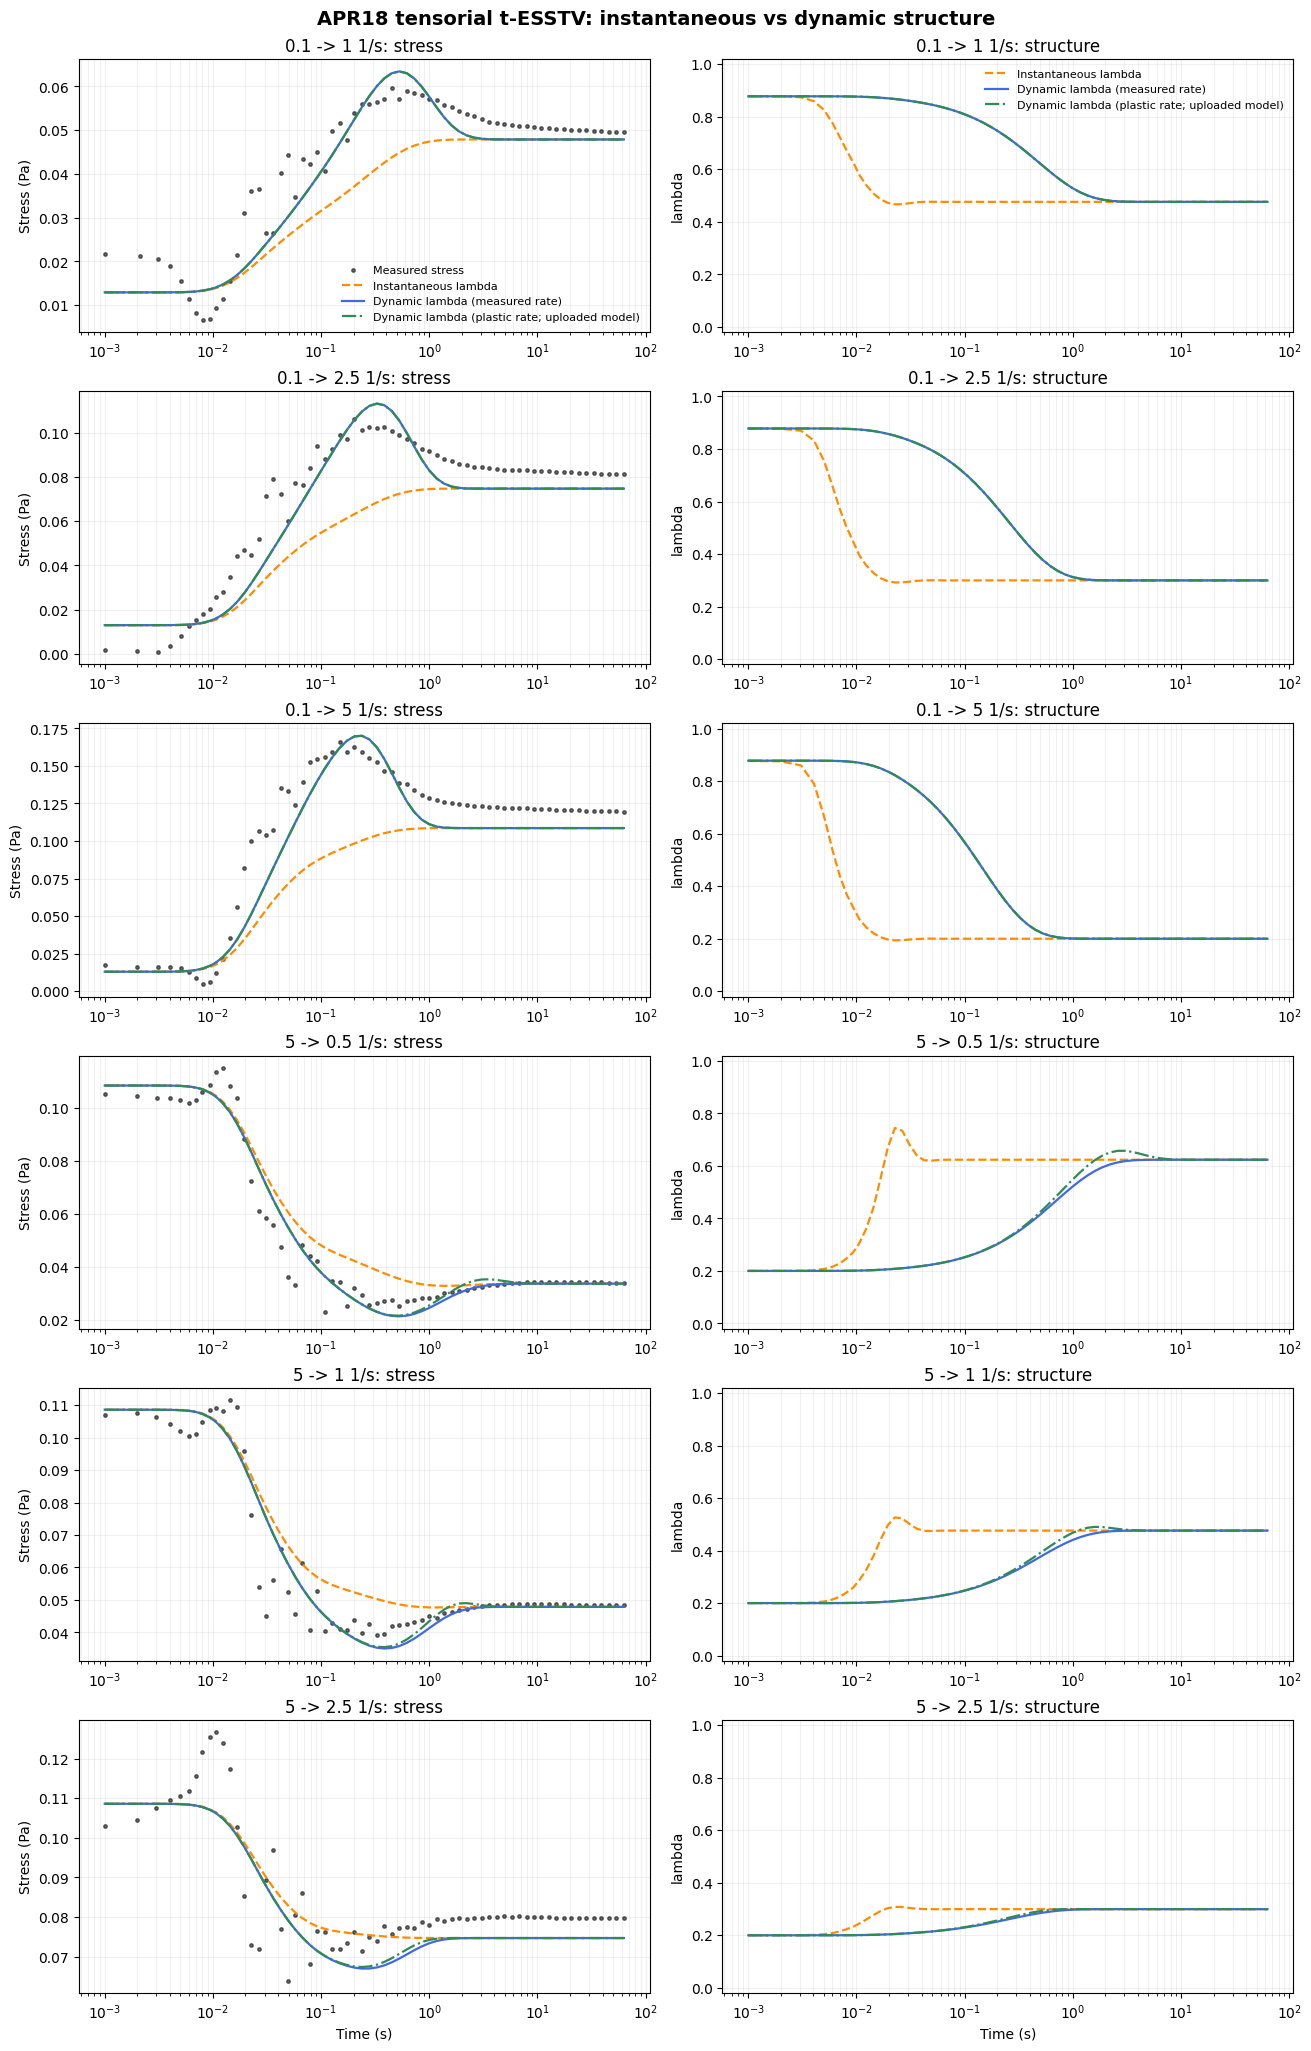

In [16]:
# ============================================================
# EXTENSION 7. STRESS AND LAMBDA COMPARISON FIGURE
# ============================================================

MODEL_STYLES = {
    "instantaneous_lambda": {
        "color": "darkorange",
        "linestyle": "--",
        "label": "Instantaneous lambda",
    },
    "dynamic_lambda_total_rate": {
        "color": "royalblue",
        "linestyle": "-",
        "label": "Dynamic lambda (measured rate)",
    },
    "dynamic_lambda_plastic_rate": {
        "color": "seagreen",
        "linestyle": "-.",
        "label": "Dynamic lambda (plastic rate; uploaded model)",
    },
}

figure, axes = plt.subplots(
    len(selected_tests),
    2,
    figsize=(13, 3.4 * len(selected_tests)),
    squeeze=False,
    constrained_layout=True,
)

for row, test in enumerate(selected_tests):
    protocol = (test.pre_rate, test.target_rate)
    stress_axis, lambda_axis = axes[row]

    reference = ablation_results[
        (protocol, "dynamic_lambda_plastic_rate")
    ]
    valid = np.isfinite(reference["stress_data"])
    if valid.any():
        stress_axis.semilogx(
            reference.loc[valid, "time_plot"],
            reference.loc[valid, "stress_data"],
            "o",
            ms=2.5,
            color="black",
            alpha=0.55,
            label="Measured stress",
        )

    for model_name, style in MODEL_STYLES.items():
        frame = ablation_results[(protocol, model_name)]
        stress_axis.semilogx(
            frame["time_plot"],
            frame["stress_model"],
            color=style["color"],
            linestyle=style["linestyle"],
            lw=1.6,
            label=style["label"],
        )
        lambda_axis.semilogx(
            frame["time_plot"],
            frame["lambda"],
            color=style["color"],
            linestyle=style["linestyle"],
            lw=1.6,
            label=style["label"],
        )

    title = f"{test.pre_rate:g} -> {test.target_rate:g} 1/s"
    stress_axis.set_title(title + ": stress")
    lambda_axis.set_title(title + ": structure")
    stress_axis.set_ylabel("Stress (Pa)")
    lambda_axis.set_ylabel("lambda")
    lambda_axis.set_ylim(-0.02, 1.02)
    stress_axis.grid(True, which="both", alpha=0.18)
    lambda_axis.grid(True, which="both", alpha=0.18)

    if row == len(selected_tests) - 1:
        stress_axis.set_xlabel("Time (s)")
        lambda_axis.set_xlabel("Time (s)")

    if row == 0:
        stress_axis.legend(frameon=False, fontsize=8)
        lambda_axis.legend(frameon=False, fontsize=8)

figure.suptitle(
    "APR18 tensorial t-ESSTV: instantaneous vs dynamic structure",
    fontsize=14,
    fontweight="bold",
)
figure.savefig(
    ABLATION_OUTPUT_DIR / "lambda_ablation_comparison.png",
    dpi=300,
    bbox_inches="tight",
)
figure.savefig(
    ABLATION_OUTPUT_DIR / "lambda_ablation_comparison.pdf",
    bbox_inches="tight",
)
plt.show()
plt.close(figure)


## Interpretation guide

Focus first on
`dynamic_memory_improvement_percent`:

- positive: dynamic measured-rate `λ(t)` predicts stress better than
  instantaneous `λ_ss`;
- approximately zero: structural memory has little measurable value
  for that protocol;
- negative: the instantaneous baseline performs better, suggesting
  that the current structural time scale may be inappropriate.

Compare the blue and orange `λ` curves near the beginning of each
step. Their long-time values should approach one another. The green
curve is the full uploaded model and is retained as a reference for
the later plastic-rate-coupling comparison.

Do not interpret the predicted `λ(t)` as directly measured. APR18
provides measured stress and shear rate, while `λ` remains a latent
model state.


## Extension 8 — Candidate improvement: asymmetric structural timescales

The original tensorial t-ESSTV model uses one common structural timescale,
$\tau_\lambda$, for both structural breakdown and recovery. The ablation
results suggest testing whether these processes require different rates.

Define the unchanged structural numerator

$$
F(\lambda,q)=
-\tau_{\mathrm{break}}|q|\lambda
+(1-\lambda)\left[|\tau_{\mathrm{aggr}}q|^d+1\right],
$$

where the original plastic shear rate is retained: $q=\dot\gamma_p$.
The candidate model is

$$
\frac{d\lambda}{dt}=
\begin{cases}
F(\lambda,\dot\gamma_p)/\tau_{\lambda,\mathrm{breakdown}}, & F<0,\\[4pt]
F(\lambda,\dot\gamma_p)/\tau_{\lambda,\mathrm{recovery}}, & F\ge 0.
\end{cases}
$$

Thus this extension changes only the structural timescale. The plastic-rate
coupling, elastic-strain equation, tensorial stress equations, measured shear
history, and steady-state target of $\lambda$ are unchanged.


In [17]:
# ============================================================
# EXTENSION 8. ASYMMETRIC BREAKDOWN/RECOVERY MODEL
# ============================================================

from scipy.optimize import least_squares


def _structure_kinematics_asymmetric(
    gdot,
    lam,
    gamma_e,
    p,
    tau_lambda_breakdown,
    tau_lambda_recovery,
):
    """Original plastic-rate kinematics with two lambda timescales."""

    lam_eff = float(np.clip(lam, 1.0e-8, 1.0))
    gamma_max = max(p.gamma0_r * lam_eff, 1.0e-10)
    ratio = float(
        np.clip(gamma_e / gamma_max, -0.999999, 0.999999)
    )

    denominator = 2.0 - ratio if gdot >= 0.0 else 2.0 + ratio
    gamma_p_dot = gdot / max(denominator, 1.0e-8)

    structural_numerator = (
        -p.tau_break * abs(gamma_p_dot) * lam_eff
        + (1.0 - lam_eff)
        * (abs(p.tau_aggr * gamma_p_dot) ** p.d + 1.0)
    )
    active_timescale = (
        tau_lambda_breakdown
        if structural_numerator < 0.0
        else tau_lambda_recovery
    )
    lambda_dot = structural_numerator / max(active_timescale, EPS)

    if lam <= 0.0 and lambda_dot < 0.0:
        lambda_dot = 0.0
    if lam >= 1.0 and lambda_dot > 0.0:
        lambda_dot = 0.0

    gamma_e_dot = gamma_p_dot - ratio * abs(gamma_p_dot)
    gamma_max_dot = p.gamma0_r * lambda_dot
    if gamma_max_dot < 0.0:
        gamma_e_dot += ratio * gamma_max_dot

    return lambda_dot, gamma_e_dot, gamma_p_dot


def _asymmetric_model_rhs(
    gdot_function,
    p,
    tau_lambda_breakdown,
    tau_lambda_recovery,
):
    """Build the eight-state RHS for the candidate model."""

    def rhs(value, state):
        lam = float(state[I_LAM])
        gamma_e = float(state[I_GAMMA_E])
        sc_xy = float(state[I_SC_XY])
        sc_xx = float(state[I_SC_XX])
        sr_xy = float(state[I_SR_XY])
        sr_xx = float(state[I_SR_XX])
        sr_yy = float(state[I_SR_YY])
        sr_zz = float(state[I_SR_ZZ])

        gdot = float(gdot_function(value))
        lambda_dot, gamma_e_dot, _ = (
            _structure_kinematics_asymmetric(
                gdot,
                lam,
                gamma_e,
                p,
                tau_lambda_breakdown,
                tau_lambda_recovery,
            )
        )
        stress_dots = _tensor_stress_derivatives(
            gdot,
            lam,
            sc_xy,
            sc_xx,
            sr_xy,
            sr_xx,
            sr_yy,
            sr_zz,
            gamma_e,
            p,
        )
        return np.array(
            [lambda_dot, gamma_e_dot, *stress_dots],
            dtype=float,
        )

    return rhs


def simulate_step_asymmetric_timescales(
    test,
    p,
    tau_lambda_breakdown,
    tau_lambda_recovery,
    initial_state=None,
):
    """Simulate one protocol with separate lambda timescales."""

    time, stress_data, shear, max_step = _prepare_step_arrays(test)

    def gdot_function(value):
        return float(
            np.interp(
                value,
                time,
                shear,
                left=shear[0],
                right=shear[-1],
            )
        )

    # The new timescales do not change the steady-state solution, so the
    # original relaxed pre-shear state remains a valid initial condition.
    state0 = (
        relaxed_steady_state(test.pre_rate, p)
        if initial_state is None
        else np.asarray(initial_state, dtype=float).copy()
    )
    rhs = _asymmetric_model_rhs(
        gdot_function,
        p,
        tau_lambda_breakdown,
        tau_lambda_recovery,
    )

    solution = solve_ivp(
        rhs,
        (time[0], time[-1]),
        state0,
        t_eval=time,
        method="LSODA",
        rtol=2.0e-7,
        atol=1.0e-9,
        max_step=max_step,
    )
    if not solution.success:
        raise RuntimeError(
            "Asymmetric-timescale simulation failed: "
            + solution.message
        )

    lam = np.clip(solution.y[I_LAM], 0.0, 1.0)
    gamma_e = solution.y[I_GAMMA_E]
    sc_xy = solution.y[I_SC_XY]
    sc_xx = solution.y[I_SC_XX]
    sr_xy = solution.y[I_SR_XY]
    sr_xx = solution.y[I_SR_XX]
    sr_yy = solution.y[I_SR_YY]
    sr_zz = solution.y[I_SR_ZZ]

    gamma_e_dot = np.empty_like(time)
    gamma_p_dot = np.empty_like(time)
    for index, (gdot, lam_value, e_value) in enumerate(
        zip(shear, lam, gamma_e)
    ):
        _, gamma_e_dot[index], gamma_p_dot[index] = (
            _structure_kinematics_asymmetric(
                float(gdot),
                float(lam_value),
                float(e_value),
                p,
                tau_lambda_breakdown,
                tau_lambda_recovery,
            )
        )

    return _assemble_ablation_frame(
        time,
        stress_data,
        shear,
        lam,
        gamma_e,
        gamma_e_dot,
        gamma_p_dot,
        sc_xy,
        sc_xx,
        sr_xy,
        sr_xx,
        sr_yy,
        sr_zz,
    )


In [18]:
# ============================================================
# EXTENSION 9. FIT THE TWO STRUCTURAL TIMESCALES
# ============================================================

# Broad positive bounds in seconds. Change them only if the optimum lands on
# a boundary and there is a physical reason to expand the search interval.
ASYMMETRIC_TAU_BOUNDS_S = (0.05, 10.0)

# Cache the original steady pre-shear states so optimisation does not repeat
# the expensive relaxation calculation at every function evaluation.
_asymmetric_initial_states = {
    float(rate): relaxed_steady_state(float(rate), PAPER_PARAMS)
    for rate in sorted({float(test.pre_rate) for test in selected_tests})
}

_valid_residual_count = sum(
    int(np.isfinite(test.data["stress"].to_numpy(float)).sum())
    for test in selected_tests
)


def _asymmetric_fit_residuals(log_timescales):
    """Equal-protocol-weight residuals for least-squares fitting."""

    tau_breakdown, tau_recovery = np.exp(log_timescales)
    residual_blocks = []

    try:
        for test in selected_tests:
            frame = simulate_step_asymmetric_timescales(
                test,
                PAPER_PARAMS,
                tau_breakdown,
                tau_recovery,
                initial_state=_asymmetric_initial_states[
                    float(test.pre_rate)
                ],
            )
            observed = frame["stress_data"].to_numpy(float)
            predicted = frame["stress_model"].to_numpy(float)
            valid = np.isfinite(observed) & np.isfinite(predicted)
            observed_valid = observed[valid]
            span = max(
                float(np.ptp(observed_valid)),
                float(np.sqrt(np.mean(observed_valid**2))),
                1.0e-6,
            )
            # Dividing by sqrt(n) gives every protocol equal total weight.
            residual_blocks.append(
                (predicted[valid] - observed_valid)
                / (span * np.sqrt(valid.sum()))
            )
    except (RuntimeError, ValueError, FloatingPointError):
        return np.full(_valid_residual_count, 1.0e3)

    return np.concatenate(residual_blocks)


_log_lower = np.log([ASYMMETRIC_TAU_BOUNDS_S[0]] * 2)
_log_upper = np.log([ASYMMETRIC_TAU_BOUNDS_S[1]] * 2)
_log_initial = np.log([PAPER_PARAMS.tau_lambda] * 2)

asymmetric_fit = least_squares(
    _asymmetric_fit_residuals,
    x0=_log_initial,
    bounds=(_log_lower, _log_upper),
    method="trf",
    max_nfev=80,
    xtol=1.0e-6,
    ftol=1.0e-6,
    gtol=1.0e-6,
)

TAU_LAMBDA_BREAKDOWN_FIT, TAU_LAMBDA_RECOVERY_FIT = np.exp(
    asymmetric_fit.x
)

asymmetric_fit_summary = pd.DataFrame(
    {
        "parameter": [
            "published_tau_lambda",
            "fitted_tau_lambda_breakdown",
            "fitted_tau_lambda_recovery",
        ],
        "value_s": [
            PAPER_PARAMS.tau_lambda,
            TAU_LAMBDA_BREAKDOWN_FIT,
            TAU_LAMBDA_RECOVERY_FIT,
        ],
    }
)
asymmetric_fit_summary["optimizer_success"] = asymmetric_fit.success
asymmetric_fit_summary["optimizer_nfev"] = asymmetric_fit.nfev
asymmetric_fit_summary.to_csv(
    ABLATION_OUTPUT_DIR / "asymmetric_timescale_fit.csv",
    index=False,
)

display(asymmetric_fit_summary)
print(asymmetric_fit.message)


,parameter,value_s,optimizer_success,optimizer_nfev
0,published_tau_lambda,1.458200,True,9
1,fitted_tau_lambda_breakdown,1.455188,True,9
2,fitted_tau_lambda_recovery,1.459321,True,9


`xtol` termination condition is satisfied.


In [19]:
# ============================================================
# EXTENSION 10. RUN AND COMPARE THE CANDIDATE MODEL
# ============================================================

ASYMMETRIC_MODEL_NAME = "dynamic_lambda_asymmetric_timescales"
asymmetric_metric_rows = []

for test in selected_tests:
    protocol = (test.pre_rate, test.target_rate)
    frame = simulate_step_asymmetric_timescales(
        test,
        PAPER_PARAMS,
        TAU_LAMBDA_BREAKDOWN_FIT,
        TAU_LAMBDA_RECOVERY_FIT,
        initial_state=_asymmetric_initial_states[float(test.pre_rate)],
    )
    ablation_results[(protocol, ASYMMETRIC_MODEL_NAME)] = frame
    frame.to_csv(
        ABLATION_OUTPUT_DIR
        / f"{safe_name(test)}__{ASYMMETRIC_MODEL_NAME}.csv",
        index=False,
    )

    original = ablation_results[
        (protocol, "dynamic_lambda_plastic_rate")
    ]
    original_score = metrics(
        original["stress_data"],
        original["stress_model"],
    )
    candidate_score = metrics(
        frame["stress_data"],
        frame["stress_model"],
    )
    asymmetric_metric_rows.append(
        {
            "protocol": f"{test.pre_rate:g}->{test.target_rate:g}",
            "original_rmse": original_score["rmse"],
            "asymmetric_rmse": candidate_score["rmse"],
            "rmse_improvement_percent": 100.0
            * (original_score["rmse"] - candidate_score["rmse"])
            / max(original_score["rmse"], EPS),
            "original_mae": original_score["mae"],
            "asymmetric_mae": candidate_score["mae"],
            "original_r2": original_score["r2"],
            "asymmetric_r2": candidate_score["r2"],
            **{
                "candidate_" + key: value
                for key, value in _lambda_transition_metrics(frame).items()
            },
        }
    )

asymmetric_comparison = pd.DataFrame(asymmetric_metric_rows)
asymmetric_comparison.to_csv(
    ABLATION_OUTPUT_DIR / "asymmetric_vs_original_metrics.csv",
    index=False,
)
display(asymmetric_comparison)

print(
    "Mean protocol RMSE improvement (%):",
    asymmetric_comparison["rmse_improvement_percent"].mean(),
)


,protocol,original_rmse,asymmetric_rmse,rmse_improvement_percent,original_mae,asymmetric_mae,original_r2,asymmetric_r2,candidate_lambda_initial,candidate_lambda_final,candidate_delta_lambda,candidate_lambda_t50_s,candidate_lambda_t90_s,candidate_lambda_memory_area_s
0,0.1->1,0.005519,0.005518,0.015370,0.004341,0.004339,0.877465,0.877502,0.878004,0.476165,-0.401839,0.383422,1.169924,0.197920
1,0.1->2.5,0.010729,0.010726,0.026870,0.009131,0.009129,0.872848,0.872916,0.878004,0.299710,-0.578294,0.202515,0.618408,0.154678
2,0.1->5,0.016975,0.016975,0.002279,0.013730,0.013730,0.872214,0.872220,0.878004,0.200172,-0.677833,0.125488,0.383423,0.106067
3,5->0.5,0.006230,0.006230,-0.005589,0.004215,0.004215,0.957289,0.957284,0.200186,0.623460,0.423274,0.527161,1.372159,0.342548
4,5->1,0.006974,0.006974,-0.006770,0.004211,0.004211,0.919111,0.919100,0.200186,0.476165,0.275979,0.326813,0.850494,0.125472
5,5->2.5,0.008264,0.008265,-0.007415,0.006801,0.006802,0.708060,0.708016,0.200186,0.299710,0.099524,0.172668,0.527168,0.021441


Mean protocol RMSE improvement (%): 0.004124098149237261


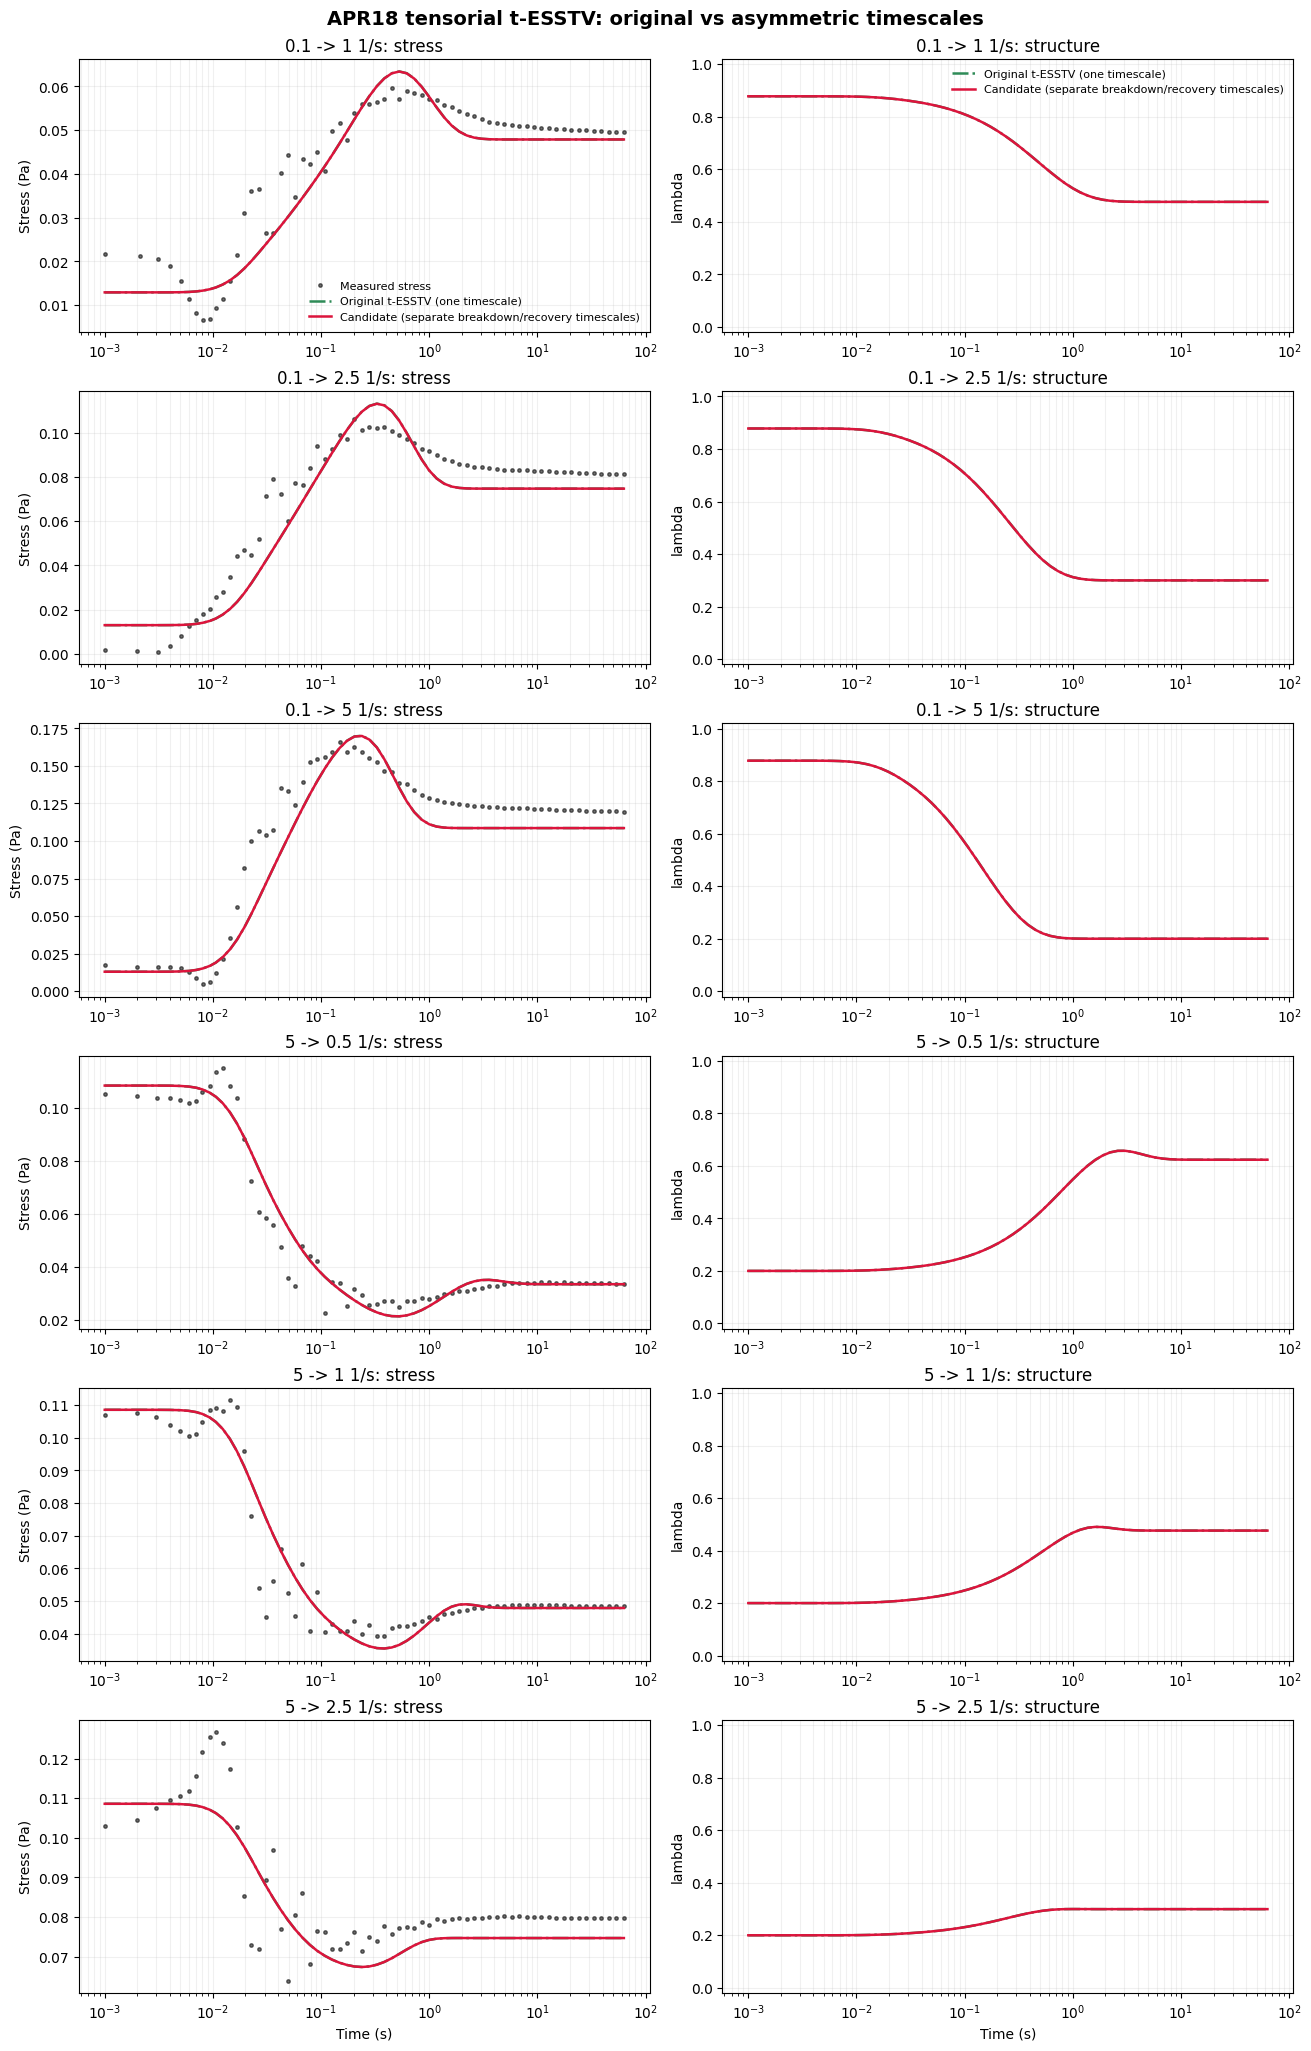

In [20]:
# ============================================================
# EXTENSION 11. ORIGINAL VS ASYMMETRIC-TIMESCALE FIGURE
# ============================================================

figure, axes = plt.subplots(
    len(selected_tests),
    2,
    figsize=(13, 3.4 * len(selected_tests)),
    squeeze=False,
    constrained_layout=True,
)

for row, test in enumerate(selected_tests):
    protocol = (test.pre_rate, test.target_rate)
    stress_axis, lambda_axis = axes[row]
    original = ablation_results[
        (protocol, "dynamic_lambda_plastic_rate")
    ]
    candidate = ablation_results[
        (protocol, ASYMMETRIC_MODEL_NAME)
    ]

    valid = np.isfinite(original["stress_data"])
    stress_axis.semilogx(
        original.loc[valid, "time_plot"],
        original.loc[valid, "stress_data"],
        "o",
        ms=2.5,
        color="black",
        alpha=0.55,
        label="Measured stress",
    )

    for frame, color, linestyle, label in [
        (
            original,
            "seagreen",
            "-.",
            "Original t-ESSTV (one timescale)",
        ),
        (
            candidate,
            "crimson",
            "-",
            "Candidate (separate breakdown/recovery timescales)",
        ),
    ]:
        stress_axis.semilogx(
            frame["time_plot"],
            frame["stress_model"],
            color=color,
            linestyle=linestyle,
            lw=1.8,
            label=label,
        )
        lambda_axis.semilogx(
            frame["time_plot"],
            frame["lambda"],
            color=color,
            linestyle=linestyle,
            lw=1.8,
            label=label,
        )

    title = f"{test.pre_rate:g} -> {test.target_rate:g} 1/s"
    stress_axis.set_title(title + ": stress")
    lambda_axis.set_title(title + ": structure")
    stress_axis.set_ylabel("Stress (Pa)")
    lambda_axis.set_ylabel("lambda")
    lambda_axis.set_ylim(-0.02, 1.02)
    stress_axis.grid(True, which="both", alpha=0.18)
    lambda_axis.grid(True, which="both", alpha=0.18)

    if row == len(selected_tests) - 1:
        stress_axis.set_xlabel("Time (s)")
        lambda_axis.set_xlabel("Time (s)")
    if row == 0:
        stress_axis.legend(frameon=False, fontsize=8)
        lambda_axis.legend(frameon=False, fontsize=8)

figure.suptitle(
    "APR18 tensorial t-ESSTV: original vs asymmetric timescales",
    fontsize=14,
    fontweight="bold",
)
figure.savefig(
    ABLATION_OUTPUT_DIR / "asymmetric_timescale_comparison.png",
    dpi=300,
    bbox_inches="tight",
)
figure.savefig(
    ABLATION_OUTPUT_DIR / "asymmetric_timescale_comparison.pdf",
    bbox_inches="tight",
)
plt.show()
plt.close(figure)


## How to interpret the fourth-model result

- Compare `fitted_tau_lambda_breakdown` and
  `fitted_tau_lambda_recovery`. A difference indicates that the data prefer
  different structural speeds, but the RMSE comparison determines whether
  that difference is practically useful.
- Positive `rmse_improvement_percent` means the asymmetric-timescale candidate
  predicts that protocol better than the original plastic-rate t-ESSTV.
- Pay particular attention to the depth and recovery of the step-down stress
  valleys and verify that any improvement does not damage the step-up peaks.
- The candidate adds one free parameter. Treat it as a genuine improvement
  only if the reduction is consistent across protocols or later remains on
  held-out protocols—not merely because the pooled fitting error is lower.
- The long-time steady-state target of $\lambda$ is unchanged. Persistent
  final-plateau bias therefore points to steady-state stress parameters rather
  than either new timescale.
